# Point Spread Function Analysis

**Part:** I — Image quality & artifacts · **Reading time:** ~75 min · **Pass 1 overview:** [Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb), [Speed, Artifacts and Safety](../pass1_big_picture/P1.5_Speed_Artifacts_and_Safety.ipynb) · **Refreshers you may want:** [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Fourier properties (shift, convolution theorem)](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

An MRI scanner never delivers the "true" object $m(\vec r)$. It delivers a version of it that has been **blurred, shifted, ringed and replicated** by the way the data were acquired. The **point spread function (PSF)** — the image the scanner would produce of a single, infinitely small point — captures *all* of these effects in one function. In this chapter we show how to use the PSF together with the MRI signal equation to predict, quantitatively, what finite sampling, relaxation during the readout, off-resonance and chemical shift do to the image. The same toolbox explains most artifacts in the next chapter, [Artifacts](I2_Artifacts.ipynb).

## Learning goals

1. Describe how images are formed
    * What is the impact of relaxation and off-resonance/chemical shift on the signal
1. Understand the constraints and trade-offs in MRI
    * How do relaxation and off-resonance/chemical shift limit the readout duration
1. Manipulate MRI sequence parameters to improve performance
    * How does the readout duration affect artifacts due to relaxation and off-resonance/chemical shift
1. Identify artifacts and how to mitigate them
    * What is the effect of relaxation and off-resonance/chemical shift during the readout on the resulting images

New in this adaptation:

5. Define the PSF, explain **linear shift-invariant (LSI)** systems and **convolution** from scratch.
6. Derive the PSF of finite, discrete k-space sampling (the **Dirichlet kernel** ≈ sinc) and explain why sampling creates **replicas** (aliasing).
7. Derive the blur from $T_2$/$T_2^*$ decay during the readout (a Lorentzian-like PSF) and relate it to blurring in fast spin echo (FSE) and echo-planar imaging (EPI).
8. Derive the image shift from off-resonance: **shift = Δf / (bandwidth per pixel)** pixels.
9. Quantify the trade-offs of **windowing/apodization** (resolution vs. sidelobes vs. SNR).

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$ | position | m | $x$ = readout (frequency-encoding) direction, $y$ = phase-encoding direction in this chapter |
| $\vec k=[k_x,k_y,k_z]^T$ | k-space position (spatial frequency) | m⁻¹ (cycles/m) | $\vec k(t)=\bar\gamma\int_0^t\vec G(\tau)d\tau$ |
| $t$, $\tau$, $\xi$ | time; dummy time variable; dummy position variable in convolution integrals | s, s, m | |
| $m(\vec r)$ | true object = transverse magnetization at the echo time | a.u. | |
| $M(\vec k)=\mathcal F\{m\}$ | k-space data (**not** the magnetization vector $\vec M$) | a.u. | |
| $\hat M(\vec k)$, $\hat m(\vec r)$ | k-space data *as actually measured* (weighted), and the reconstructed image | a.u. | hat = "what we get" |
| $W(\vec k)$ | k-space weighting function (complex): every imperfection that multiplies the data | – | $W=1$ for a perfect acquisition |
| $w(\vec r)=\mathcal F^{-1}\{W\}$ | PSF belonging to the weighting $W$ | m⁻¹ (per dimension) | |
| $h(x)$ | PSF of finite, discrete sampling alone | m⁻¹ | Dirichlet kernel ≈ sinc |
| $*$ | convolution (in this chapter never complex conjugation) | | |
| $\delta(x)$ | Dirac delta ("a point") | m⁻¹ | not the resolution! |
| $\mathcal F\{\cdot\}$, $\mathcal F^{-1}\{\cdot\}$ | Fourier transform / inverse, kernel $e^{-i2\pi kx}$ / $e^{+i2\pi kx}$ | | |
| $\mathrm{sinc}(u)$ | $\sin(\pi u)/(\pi u)$ | – | FT of rect |
| $\mathrm{rect}(u)$ | 1 for $|u|<1/2$, else 0 | – | |
| $N$ ($N_x$, $N_y$, $N_{PE}$) | number of k-space samples (matrix size) | – | 64–512 |
| $p$ | integer sample index, $-N/2\le p<N/2$ | – | |
| $\Delta k$ | k-space sample spacing | m⁻¹ | $=1/FOV$ |
| $k_{max}$ | largest sampled spatial frequency | m⁻¹ | $\approx N\Delta k/2$ |
| $FOV$ | field of view | m | 0.2–0.4 m |
| $\Delta x=FOV/N$ | pixel size (also written $\delta$) | m | 0.5–3 mm |
| $FWHM$ | full width at half maximum of the PSF | m or pixels | 1.21 pixels for plain sampling |
| $s(t)$, $s_n(t)$ | received signal (of coil $n$) | V (a.u.) | |
| $C_n(\vec r)$ | complex receive sensitivity of coil $n$ | – | |
| $T_2$, $T_2^*$, $T_2'$ | transverse relaxation time; effective (incl. field inhomogeneity) time; inhomogeneity part, $1/T_2^*=1/T_2+1/T_2'$ | s | brain at 3 T: $T_2\approx$ 70–100 ms, $T_2^*\approx$ 40–60 ms |
| $\Delta f_{cs}$ | chemical-shift frequency offset | Hz | fat ≈ −3.5 ppm ≈ −447 Hz at 3 T |
| $\Delta f_r(\vec r)=\bar\gamma\Delta B_0(\vec r)$ | off-resonance from field inhomogeneity / susceptibility | Hz | 0–few 100 Hz |
| $\Delta f(\vec r)$, $\Delta f_0$ | total frequency offset; a single, spatially constant value of it | Hz | |
| $\vec G(t)$, $G_{x}$ | gradient; readout gradient amplitude | T/m | 5–40 mT/m |
| $\gamma$, $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio | rad s⁻¹ T⁻¹, Hz/T | 42.58 MHz/T for ¹H |
| $\upsilon(\vec k)$ | **time map**: the time (after excitation) at which k-space point $\vec k$ is sampled | s | Greek "upsilon" |
| $TE$ | echo time (time at which $\vec k=0$ is sampled) | s | 1–100 ms |
| $\Delta t$ | dwell time between readout samples | s | 2–20 µs |
| $BW_{read}=1/\Delta t$ | total receiver (readout) bandwidth (the original calls it $RBW$) | Hz | 15–250 kHz |
| $BW_{pix}=BW_{read}/N_x$ | bandwidth **per pixel** | Hz/pixel | 100–1000 Hz in 2DFT |
| $T_{read}=N_x\Delta t$ | readout duration | s | 2–10 ms |
| $t_{esp}$ | echo spacing (EPI, FSE) | s | EPI 0.4–1 ms; FSE 5–15 ms |
| $BW_{PE}=1/t_{esp}$ | EPI "phase-encoding bandwidth" (total) | Hz | 1–2.5 kHz |
| $ETL$ | echo train length (echoes per excitation) | – | FSE 4–32; EPI 32–128 |
| $T_{trav}$ | time needed to traverse k-space along one direction ($T_{read}$ in readout; $N_{PE}t_{esp}$ in EPI phase encoding) | s | |
| $a$ | decay constant of an exponential k-space weighting | m | $a=FOV/(BW\,T_2^*)$ |
| $i$ | imaginary unit, $i^2=-1$ | – | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. What is a point spread function?

### 1.1 The image of a point

Imagine an object that is a single, infinitely small bright dot at position $x_0$. Mathematically this is a **Dirac delta**, $m(x)=\delta(x-x_0)$: zero everywhere except at $x_0$, with unit total "area" ($\int\delta(x)\,dx=1$). A perfect imaging system would return exactly that dot. A real system returns a small blob — possibly with ripples, possibly displaced. That blob is the **point spread function** (PSF), also called the **impulse response**.

> **🧭 Intuition:** The PSF is the "brush stroke" of the imaging system. However detailed the object, the system can only paint it with this brush. A wide brush = blurry image; a brush with fringes = ringing; a brush that lands somewhere else = shifted image.

### 1.2 Linear shift-invariant (LSI) systems and convolution

Two properties turn the PSF from a curiosity into a complete description of the imaging system:

* **Linearity:** the image of $a\,m_1+b\,m_2$ is $a\,\hat m_1+b\,\hat m_2$. MRI is linear because the signal equation is an integral over the object (and integrals are linear) and the reconstruction (an inverse FFT) is linear.
* **Shift invariance:** if the object is moved by $\xi$, the image moves by $\xi$ and is otherwise unchanged. For MRI this holds as long as the k-space weighting $W(\vec k)$ is the same for every location (it fails, e.g., when $T_2^*$ or off-resonance varies with position — we deal with that by splitting the object into components, Section 3).

Any object can be written as a "sum" (integral) of shifted, weighted points:

$$m(x)=\int m(\xi)\,\delta(x-\xi)\,d\xi$$

In words: the object is a superposition of dots at every position $\xi$, each with brightness $m(\xi)$.
Where: $\xi$ = dummy integration variable [m] running over all positions; $\delta(x-\xi)$ = a dot located at $\xi$.

Apply the system: by linearity each dot is imaged separately; by shift invariance the image of the dot at $\xi$ is the PSF moved to $\xi$, i.e. $h(x-\xi)$. Adding them up:

$$\hat m(x)=\int m(\xi)\,h(x-\xi)\,d\xi \;\equiv\; (m*h)(x)$$

In words: **the image is the object convolved with the PSF** — every point of the object is replaced by a copy of the PSF centred on it, scaled by the brightness of that point, and all copies are added.
Where: $\hat m(x)$ = reconstructed image; $h$ = PSF; $*$ = the **convolution** operation defined by the integral.

The discrete version (what numpy computes) replaces the integral by a sum over pixels $j$: $(m*h)[n]=\sum_j m[j]\,h[n-j]$.

### 1.3 The convolution theorem (why the PSF is so easy to compute in MRI)

> **🔁 Refresher:** The **convolution theorem** says $\mathcal F\{m*h\}=\mathcal F\{m\}\cdot\mathcal F\{h\}$: convolution in one domain is plain multiplication in the other. See [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb).

MRI measures data in k-space, $M(\vec k)=\mathcal F\{m\}$. If the acquisition **multiplies** the data by some weighting $W(\vec k)$, then by the convolution theorem the image is **convolved** with $w=\mathcal F^{-1}\{W\}$. So: *to find the PSF, write down what multiplies k-space and inverse-Fourier-transform it.* That is the whole method of this chapter.

The next cell checks the two facts numerically: (1) convolving an object with a PSF directly, and (2) multiplying their DFTs and transforming back, give the same result. (The DFT version is a *circular* convolution — the PSF wraps around the array edges — which is exactly what happens in MRI, see Section 2.3.)

max |direct - via_fft| = 4.440892098500626e-16


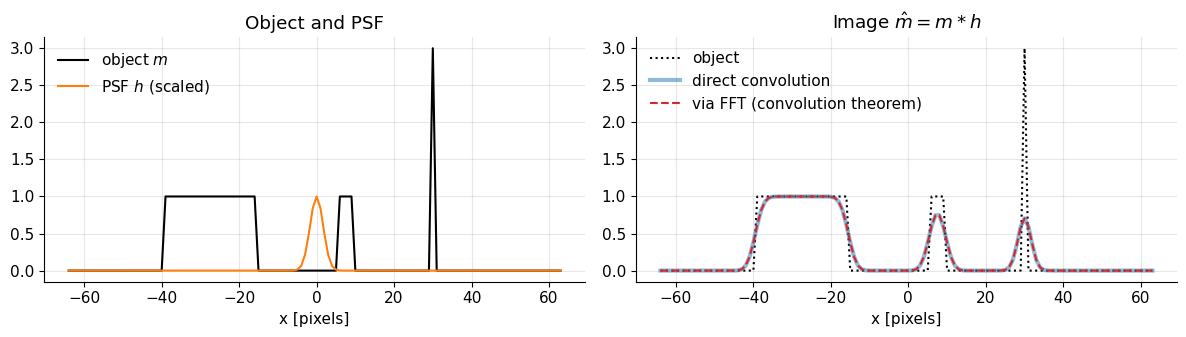

In [2]:
# A 1D object: a wide block, a narrow block and a single bright "point" (a delta)
N = 128
x = np.arange(N) - N // 2                       # pixel index, 0 in the middle
obj = np.zeros(N)
obj[(x > -40) & (x < -15)] = 1.0               # wide block
obj[(x > 5) & (x < 10)] = 1.0                  # narrow block
obj[x == 30] = 3.0                              # a point

# An example PSF: a Gaussian blob with FWHM = 4 pixels (centred at index N//2)
fwhm_px = 4.0
h = np.exp(-4 * np.log(2) * x**2 / fwhm_px**2)
h /= h.sum()                                    # unit area -> brightness preserved

# (1) direct circular convolution: sum_j obj[j] h[n-j]  (explicit double loop, to show the definition)
direct = np.zeros(N)
for n in range(N):
    for j in range(N):
        direct[n] += obj[j] * h[(n - j + N // 2) % N]   # h is centred at N//2, wrap indices

# (2) convolution theorem: multiply the (centred) DFTs, transform back
via_fft = np.real(mt.ifftc(mt.fftc(obj) * mt.fftc(h)) * np.sqrt(N))   # ortho-normalised FFTs need sqrt(N)

print("max |direct - via_fft| =", np.abs(direct - via_fft).max())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(x, obj, "k", label="object $m$")
ax[0].plot(x, h / h.max(), "C1", label="PSF $h$ (scaled)")
ax[0].set_xlabel("x [pixels]"); ax[0].legend(); ax[0].set_title("Object and PSF")
ax[1].plot(x, obj, "k:", label="object")
ax[1].plot(x, direct, "C0", lw=3, alpha=0.5, label="direct convolution")
ax[1].plot(x, via_fft, "C3--", label="via FFT (convolution theorem)")
ax[1].set_xlabel("x [pixels]"); ax[1].legend(); ax[1].set_title(r"Image $\hat m = m * h$")
plt.tight_layout(); plt.show()

The two computations agree to machine precision. Note how the *point* is imaged as a copy of the PSF (scaled by 3), the wide block keeps its height but gets soft edges, and the narrow block — only slightly wider than the PSF — loses peak height: **small objects lose contrast when the PSF is wide**.

## 2. The PSF of finite k-space sampling

Before looking at any "imperfection", note that *every* MRI image already has a non-trivial PSF, simply because we only measure a **finite number of discrete samples** of k-space.

### 2.1 Derivation: the Dirichlet kernel

Consider 1D Cartesian sampling: we measure $N$ samples at $k_p=p\,\Delta k$ with $p=-N/2,\dots,N/2-1$, and reconstruct with an inverse DFT evaluated at any (continuous) position $x$:

$$\hat m(x)=\sum_{p=-N/2}^{N/2-1}M(p\Delta k)\,e^{+i2\pi p\Delta k\,x}$$

In words: the reconstruction adds up the measured spatial-frequency components, each multiplied by the complex wave it represents.
Where: $M(k)=\int m(\xi)e^{-i2\pi k\xi}d\xi$ is the true k-space (Fourier transform of the object), $\Delta k$ [m⁻¹] the sample spacing, $p$ the integer sample index, $N$ the number of samples.

<details><summary><b>📐 Derivation (optional): from the sum to a convolution with the Dirichlet kernel</b></summary>

Insert the definition of $M$ and swap sum and integral (both are linear):

$$\hat m(x)=\sum_p\int m(\xi)e^{-i2\pi p\Delta k\,\xi}d\xi\;e^{i2\pi p\Delta k\,x}=\int m(\xi)\underbrace{\sum_p e^{i2\pi p\Delta k\,(x-\xi)}}_{h(x-\xi)}d\xi=(m*h)(x).$$

So the PSF is $h(x)=\sum_{p=-N/2}^{N/2-1}z^p$ with $z=e^{i\theta}$, $\theta=2\pi\Delta k\,x$. This is a **geometric series**, $\sum_{p=a}^{b}z^p=z^a\frac{z^{b-a+1}-1}{z-1}$:

$$h(x)=z^{-N/2}\frac{z^{N}-1}{z-1}=z^{-N/2}\frac{z^{N/2}\left(z^{N/2}-z^{-N/2}\right)}{z^{1/2}\left(z^{1/2}-z^{-1/2}\right)}=z^{-1/2}\,\frac{\sin(N\theta/2)}{\sin(\theta/2)},$$

using $z^{a}-z^{-a}=2i\sin(a\theta)$. Substituting $\theta$ back gives the result below. The extra factor $z^{-1/2}=e^{-i\pi\Delta k x}$ is a small linear phase that appears because the sampling is not exactly symmetric (one more sample at $-k$ than at $+k$); it does not change $|h|$.

</details>

$$h(x)=e^{-i\pi\Delta k\,x}\;\frac{\sin(\pi N\Delta k\,x)}{\sin(\pi\Delta k\,x)}\;\approx\;N\,\mathrm{sinc}\!\left(\frac{x}{\Delta x}\right)\quad\text{for }|x|\ll FOV$$

In words: the PSF of sampling $N$ points of k-space is a **Dirichlet kernel** (a "periodic sinc"). Near its centre it is a sinc whose zeros are spaced exactly one pixel apart.
Where: $\Delta x=FOV/N=1/(N\Delta k)$ = pixel size [m]; $FOV=1/\Delta k$ [m]; the approximation uses $\sin u\approx u$ for small $u$.

Key properties (verify them in the plots below):

| Property | Value | Consequence |
|---|---|---|
| Peak height | $N$ (we normalise to 1) | |
| Zeros | at $x=\pm\Delta x,\pm2\Delta x,\dots$ | a point *exactly* at a pixel centre appears as a single pixel |
| Main-lobe FWHM | $\approx1.21\,\Delta x$ | the *true* resolution is a bit worse than the pixel size |
| First sidelobe | −21.7 % of the peak (−13.3 dB) | **Gibbs ringing** at sharp edges |
| Period | $1/\Delta k=FOV$ | **replicas** → aliasing (Section 2.3) |

> **🔁 Refresher:** rect ↔ sinc and sampling ↔ replication are the two Fourier pairs used here: [Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb).

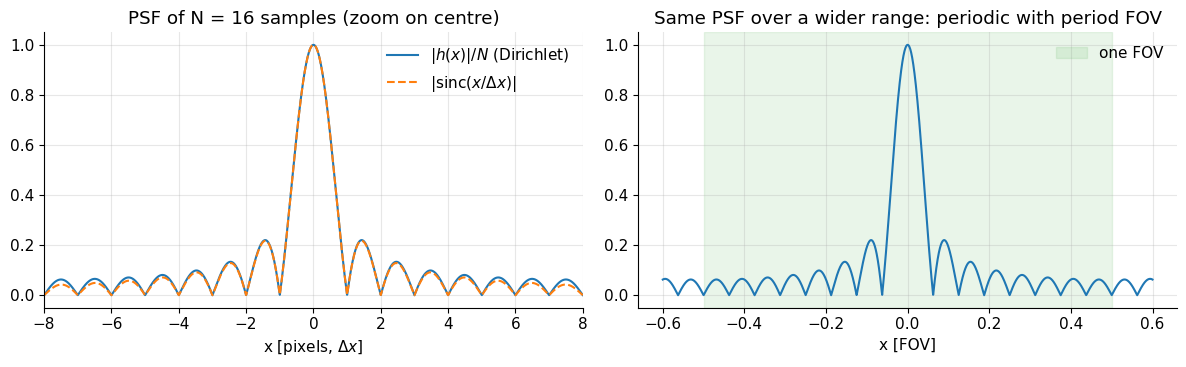

FWHM ~ 1.21 pixels; first sidelobe = -0.212 of peak


In [3]:
# Compare the exact Dirichlet kernel with its sinc approximation (FOV = 1 for simplicity)
N = 16
FOV = 1.0
dk = 1 / FOV
dx = FOV / N
xc = np.linspace(-0.6, 0.6, 4001) * FOV          # continuous positions [FOV units]
with np.errstate(invalid="ignore", divide="ignore"):
    dirichlet = np.sin(np.pi * N * dk * xc) / np.sin(np.pi * dk * xc)
dirichlet[np.isnan(dirichlet)] = N                # limit at x = 0
dirichlet = dirichlet.astype(complex)
dirichlet *= np.exp(-1j * np.pi * dk * xc)        # the small linear phase from asymmetric sampling
sinc_approx = N * np.sinc(xc / dx)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(xc / dx, np.abs(dirichlet) / N, label=r"$|h(x)|/N$ (Dirichlet)")
ax[0].plot(xc / dx, np.abs(sinc_approx) / N, "--", label=r"$|\mathrm{sinc}(x/\Delta x)|$")
ax[0].set_xlabel(r"x [pixels, $\Delta x$]"); ax[0].set_xlim(-8, 8); ax[0].legend()
ax[0].set_title(f"PSF of N = {N} samples (zoom on centre)")
ax[1].plot(xc / FOV, np.abs(dirichlet) / N)
ax[1].axvspan(-0.5, 0.5, color="C2", alpha=0.1, label="one FOV")
ax[1].set_xlabel("x [FOV]"); ax[1].set_title("Same PSF over a wider range: periodic with period FOV")
ax[1].legend(); plt.tight_layout(); plt.show()

# measure FWHM and first sidelobe numerically
a = np.abs(dirichlet) / N
c = np.argmax(a)
half = np.where(a[c:] < 0.5)[0][0]
print(f"FWHM ~ {2 * (xc[c + half] - xc[c]) / dx:.2f} pixels;",
      f"first sidelobe = {np.real(dirichlet[(xc > 1.0 * dx) & (xc < 2.0 * dx)]).min() / N:.3f} of peak")

Near the centre, the Dirichlet kernel and the sinc are indistinguishable; the difference only shows far out, where the Dirichlet kernel **comes back** at $x=\pm FOV$. The measured FWHM ≈ 1.21 pixels and the first negative sidelobe ≈ −0.21 (−0.217 for the pure sinc; the Dirichlet kernel of only 16 samples differs slightly) confirm the table.

### 2.2 A point that is not on the pixel grid

A very common confusion: "if I image a point source, I get a single bright pixel, so where is the sinc?" The answer: the reconstructed image *samples* the PSF at the pixel centres. If the point lies exactly on a pixel centre, all other samples fall on the zeros of the sinc. If it lies between pixels, the sidelobes show up.

The k-space of a point at $x_0$ is simply $M(k)=e^{-i2\pi kx_0}$ (the shift theorem), so we can simulate it exactly — no approximation from an underlying pixel grid.

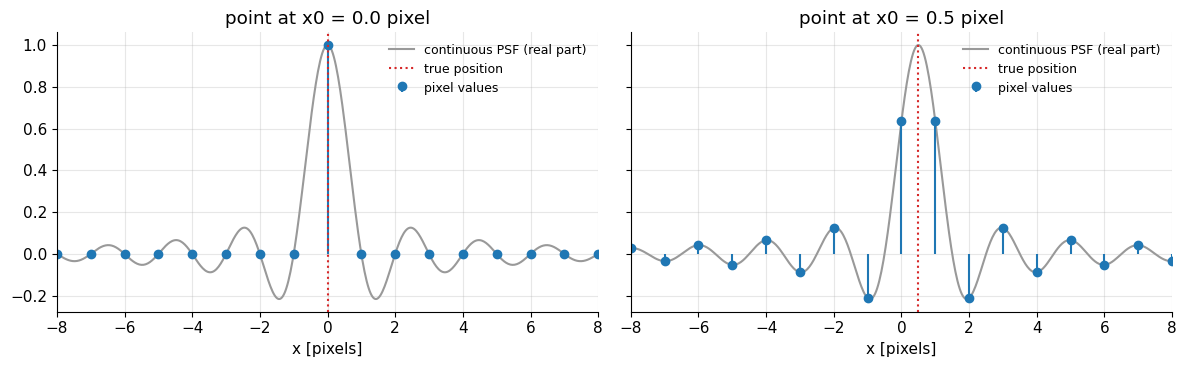

In [4]:
N = 32
p = np.arange(N) - N // 2                         # sample index
FOV = 1.0
k = p / FOV                                       # k-space positions [cycles/FOV]
xpix = p * FOV / N                                # pixel centres

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a_, x0_pix in zip(ax, [0.0, 0.5]):
    x0 = x0_pix * FOV / N
    M = np.exp(-1j * 2 * np.pi * k * x0)                          # analytic k-space of a delta at x0
    img = mt.ifftc(M, norm="backward")                            # pixel image (peak <= 1)
    # "continuous" image: zero-pad k-space 32x to evaluate the reconstruction between pixels
    Mz = np.zeros(32 * N, complex); Mz[16 * N - N // 2:16 * N + N // 2] = M
    img_fine = mt.ifftc(Mz, norm="backward") * 32
    xfine = (np.arange(32 * N) - 16 * N) * FOV / (32 * N)
    a_.plot(xfine * N / FOV, np.real(img_fine), color="0.6", label="continuous PSF (real part)")
    a_.stem(xpix * N / FOV, np.real(img), basefmt=" ", label="pixel values")
    a_.axvline(x0_pix, color="C3", ls=":", label="true position")
    a_.set_xlim(-8, 8); a_.set_xlabel("x [pixels]")
    a_.set_title(f"point at x0 = {x0_pix} pixel"); a_.legend(fontsize=9)
plt.tight_layout(); plt.show()

Left: on-grid point → one pixel, all others exactly zero (they sit on the PSF's zeros). Right: the same point half a pixel off → two equal pixels and a slowly decaying tail of alternating sign. The PSF is the same in both cases; only *where we sample it* differs. Real anatomy is never aligned with the pixel grid, so the sidelobes are always there.

### 2.3 Sampling creates replicas: aliasing

Because $h(x)$ is periodic with period $FOV$, an object point at $x$ contributes not only at $x$ but at $x\pm FOV$, $x\pm2FOV$, … . Inside the reconstructed FOV these copies land on top of each other: anything outside the FOV is **folded back** ("wrap-around", aliasing).

> **📐 Math note:** Sampling k-space with spacing $\Delta k$ multiplies $M(k)$ by a Dirac comb $\Delta k\sum_p\delta(k-p\Delta k)$. The FT of a comb with spacing $\Delta k$ is a comb with spacing $1/\Delta k=FOV$, and multiplying by a comb ⇒ convolving with a comb ⇒ the image is **replicated** every $FOV$. The finite number of samples (a rect of width $N\Delta k$) adds the sinc. Together they make the Dirichlet kernel. See [Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb).

In the readout direction the analog anti-aliasing filter of the receiver suppresses signal from outside the FOV (see [Artifacts](I2_Artifacts.ipynb)), so aliasing in practice appears in the **phase-encoding** direction(s). The demo below simulates an object that is wider than the FOV, using analytic k-space (a rect of width $L$ has $M(k)=L\,\mathrm{sinc}(kL)$).

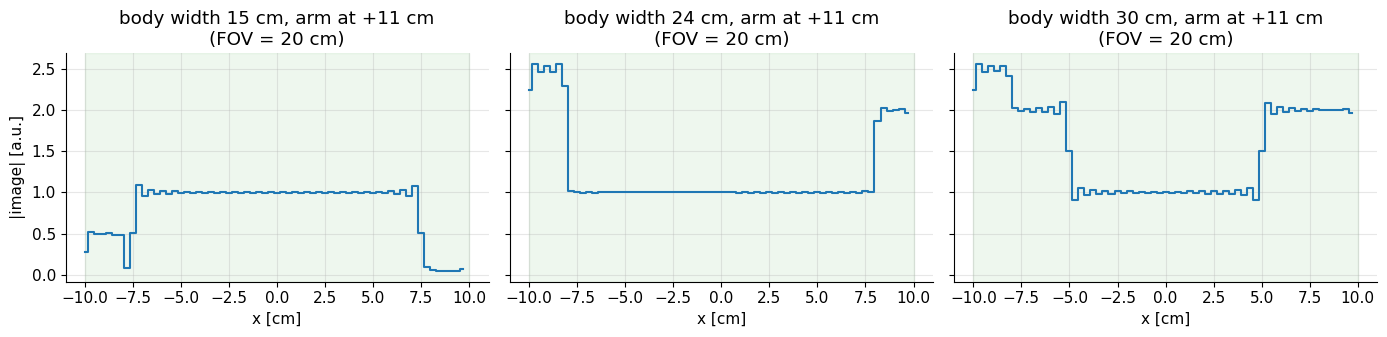

In [5]:
N = 64
FOV = 0.20                                    # [m]
k = (np.arange(N) - N // 2) / FOV             # [1/m]
x = (np.arange(N) - N // 2) * FOV / N         # pixel positions [m]

def rect_kspace(k, L, xc=0.0):
    """Analytic FT of a block of width L [m] centred at xc [m]: L sinc(kL) exp(-i 2 pi k xc)."""
    return L * np.sinc(k * L) * np.exp(-1j * 2 * np.pi * k * xc)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for a_, L in zip(ax, [0.15, 0.24, 0.30]):
    M = rect_kspace(k, L, xc=0.0) + 0.5 * rect_kspace(k, 0.02, xc=0.11)   # body + a small "arm" at x = 11 cm
    img = np.abs(mt.ifftc(M, norm="backward")) * N / FOV    # scale so that a block of height 1 reads ~1
    a_.plot(x * 100, img, drawstyle="steps-mid")
    a_.axvspan(-FOV / 2 * 100, FOV / 2 * 100, color="C2", alpha=0.08)
    a_.set_title(f"body width {L*100:.0f} cm, arm at +11 cm\n(FOV = {FOV*100:.0f} cm)")
    a_.set_xlabel("x [cm]")
ax[0].set_ylabel("|image| [a.u.]")
plt.tight_layout(); plt.show()

With a 15 cm body in a 20 cm FOV everything is fine except the small "arm" at +11 cm, which lies outside the FOV (±10 cm) and reappears at $11-20=-9$ cm. When the body itself is wider than the FOV (middle, right), its edges fold over and add to the opposite side — the bright overlap regions are classic wrap-around.

### 2.4 Two dimensions

For Cartesian sampling on a rectangular grid, the weighting is separable, $W(k_x,k_y)=W_x(k_x)W_y(k_y)$, and so is the PSF: $h(x,y)=h_x(x)\,h_y(y)$ (see [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)). The 2D PSF is therefore a "cross" of sinc sidelobes along the two axes.

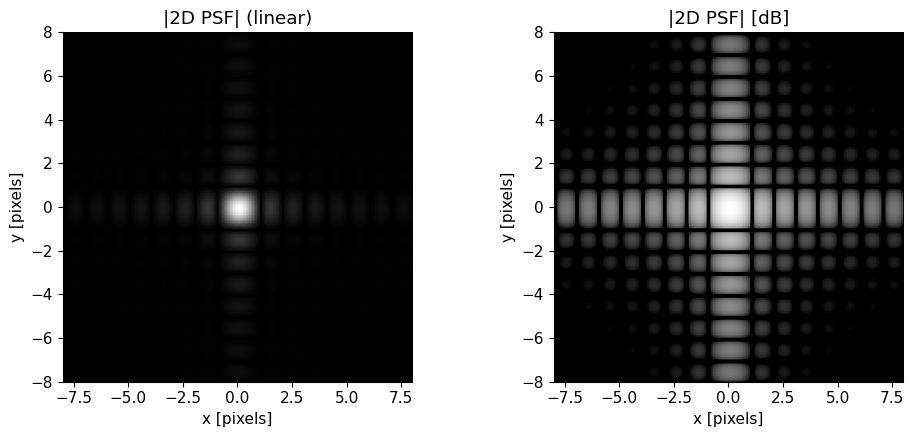

In [6]:
N = 32
Mz = np.zeros((8 * N, 8 * N), complex)
c = 4 * N
Mz[c - N // 2:c + N // 2, c - N // 2:c + N // 2] = 1.0          # N x N fully sampled k-space of a point at the origin
psf2 = mt.ifft2c(Mz, norm="backward") * 64                       # 8x zero-padding -> fine display grid
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ext = [-N / 2, N / 2, -N / 2, N / 2]                              # display extent in pixels
mt.show_image(np.abs(psf2), ax=ax[0], title="|2D PSF| (linear)", extent=ext)
mt.show_image(20 * np.log10(np.abs(psf2) + 1e-4), ax=ax[1], title="|2D PSF| [dB]", vmin=-50, vmax=0, extent=ext)
for a_ in ax:
    a_.set_xlim(-8, 8); a_.set_ylim(-8, 8); a_.set_xlabel("x [pixels]"); a_.set_ylabel("y [pixels]")
plt.tight_layout(); plt.show()

The log display shows the separable structure: sidelobes run along the $x$ and $y$ axes only (products of two small sidelobes along the diagonals are much weaker). This is why Gibbs ringing in images appears as lines parallel to edges.

## 3. The general framework: signal equation and k-space weighting

### 3.1 The comprehensive MRI signal equation

To assess the effects of imperfections on the images, we start with a comprehensive version of the MRI signal equation ([MRI Signal Equation](C2_MRI_Signal_Equation.ipynb)), including relaxation, coil sensitivity, off-resonance and chemical shift, and gradients. The signal from an individual RF coil element $n$ is

$$s_n(t) = \int m(\vec{r})\ C_n(\vec{r})\ e^{-t/T_2^*(\vec{r})}\ e^{-i 2 \pi \Delta f_{cs} t}\, e^{-i 2 \pi \Delta f_r(\vec{r}) t} \  \exp\left( -i \gamma \int_0^t \vec{G}(\tau) \cdot \vec{r} \ d\tau \right) \  d\vec{r}$$

In words: every location contributes its magnetization $m(\vec r)$, weighted by how well coil $n$ "sees" it ($C_n$), reduced by relaxation, and rotated in phase by its frequency offsets and by the gradients; the coil receives the sum over all locations.
Where: $s_n(t)$ = demodulated signal of coil $n$ [V, a.u.]; $t$ = time since excitation [s]; $m(\vec r)$ = transverse magnetization right after excitation [a.u.]; $C_n(\vec r)$ = complex receive sensitivity [–]; $T_2^*(\vec r)$ [s]; $\Delta f_{cs}$ = chemical shift [Hz]; $\Delta f_r(\vec r)$ = off-resonance from field inhomogeneity [Hz]; $\gamma$ [rad s⁻¹ T⁻¹]; $\vec G(\tau)$ [T/m]. The minus signs in the exponents follow the clockwise-precession convention ($M_{xy}\propto e^{-i\omega t}$) used throughout this course.

Using $\vec k(t)=\bar\gamma\int_0^t\vec G(\tau)d\tau$ (so that $\gamma\int\vec G\cdot\vec r\,d\tau=2\pi\vec k\cdot\vec r$), this is typically written

$$s_n(t) = \int m(\vec{r})\ C_n(\vec{r})\ e^{-t/T_2^*(\vec{r})}\ e^{-i 2 \pi \Delta f_{cs} t}\, e^{-i 2 \pi \Delta f_r(\vec{r}) t} \  e^{-i 2 \pi \vec{k}(t) \cdot \vec{r}} \  d\vec{r}$$

In words: without the "imperfection" factors ($C_n=1$, no decay, no frequency offsets) this is exactly a Fourier transform of $m$ evaluated at $\vec k(t)$ — the basis of all of MRI.

Note that this describes the signal behaviour *between* RF pulses. Incorporating RF pulses can be done either through rotation matrices or some solution of the Bloch equation such as numerical solvers or phase graphs ([Bloch Equation](A2_Bloch_Equation.ipynb), [Gradient and Spin Echoes](D3_Gradient_and_Spin_Echoes.ipynb)).

### 3.2 K-space data weighting

A powerful framework for characterizing the effects of imperfections is to define a **k-space weighting** that determines the signal modulation. Expressing this generally, we define a weighting function $W(\vec{k})$ that can be complex-valued and capture amplitude and phase modulations. Then

$$\hat{M}(\vec{k}) = M(\vec{k})\, W(\vec{k})$$

In words: what we actually measure at k-space point $\vec k$ is the ideal value times a known (or modelled) factor.

$$\hat{m}(\vec{r}) = m(\vec{r}) * \mathcal{F}^{-1} \{ W(\vec{k}) \} = m(\vec{r}) * w(\vec{r})$$

In words: by the convolution theorem, the reconstructed image is the true image convolved with $w$.
Where: $w(\vec{r})=\mathcal F^{-1}\{W\}$ is the inverse Fourier transform of the weighting function — the **point spread function (PSF)** or impulse response belonging to $W$; $*$ is convolution. (The finite-sampling PSF $h$ of Section 2 is always there as well: the total PSF is $h*w$. In the numerical demos both are included automatically because we work with finite arrays.)

Thus the effects can be boiled down to a convolution operation in the reconstructed image.

### 3.3 Spatially varying effects: decompose the object

When the frequency shift and relaxation rates vary across space, $W$ is different for different locations and the system is no longer shift-invariant. It is then helpful to decompose the image into components $m_i$ that experience the same weighting $W_i$ (e.g. same frequency shift, or same $T_2^*$):

$$ m(\vec{r}) = \sum_i m_i(\vec{r}) $$

Since the Fourier transform is linear,

$$\hat{M}(\vec{k}) = \sum_i M_i(\vec{k})\, W_i(\vec{k}) $$

$$\hat{m}(\vec{r}) =\sum_i m_i(\vec{r}) * w_i(\vec{r})$$

In words: each component is convolved with its own convolution kernel, and the results add.
Where: $M_i=\mathcal F\{m_i\}$, $w_i=\mathcal F^{-1}\{W_i\}$.

For example, to analyze chemical shift we can divide our image into water, $m_1(\vec{r})$, and fat, $m_2(\vec{r})$, components; then $W_1(\vec{k}) = 1$, $W_2(\vec{k}) = e^{-i 2 \pi\ \upsilon(\vec{k}) \Delta f_{fat}}$ (with the time map $\upsilon$ defined in Section 4), and the resulting image will be

$$\hat{m}(\vec{r}) = m_1(\vec{r}) + m_2(\vec{r}) * w_2(\vec{r})$$

providing an accurate image of the water component but a corrupted fat image (typically shifted in space for Cartesian trajectories).

The k-space data weighting concept is very powerful. It can include frequency shifts. It can include weighting from all types of relaxation ($T_1, T_2, T_2^*$) from more complex acquisition strategies such as SSFP and fast spin echoes. It can include diffusion weighting, flow effects, deliberate filtering (windowing, Section 7), and more.

> **⚠️ Common confusion:** $M(\vec k)$ here is k-space data, *not* the magnetization vector $\vec M$. Larson's notation uses the same letter; we always say which is meant.

## 4. Relaxation during signal acquisition

To examine the effects of relaxation, we neglect coil sensitivity, off-resonance and chemical shift. Relaxation modulates the received signal over time. This creates a weighting in k-space, which leads to image filtering (often blurring). This weighting is spatially varying, depending on the relaxation of different tissues.

$$s(t) = \int m(\vec{r})\ e^{-t/T_2^*(\vec{r})}\  e^{-i 2 \pi \vec{k}(t) \cdot \vec{r}} \  d\vec{r}$$

In words: the same Fourier integral as before, but each location's contribution fades with its own $T_2^*$.

To interpret the effect of relaxation, consider a single value $T_2^*(\vec{r}) = T_2^*$, in which case it can be taken out of the integral:

$$s(t) = e^{-t/T_2^*} \int m(\vec{r})\ e^{-i 2 \pi \vec{k}(t) \cdot \vec{r}} \  d\vec{r} = M(\vec{k}(t))\  e^{-t/T_2^*} $$

In words: relaxation leads to **amplitude modulation** of the data as we move through k-space.

To see the effect on image formation, we introduce the **time map** $\upsilon(\vec{k})$: the time (after excitation) at which the k-space point $\vec k$ is acquired, taking into account the whole trajectory and all TRs. Then

$$\hat{M}(\vec{k}) = M(\vec{k})\, e^{- \upsilon(\vec{k}) / T_2^*}$$

Examples of $\upsilon(\vec{k})$ are shown below. In the PSF framework the k-space weighting function is

$$W(\vec{k}) = e^{- \upsilon(\vec{k}) / T_2^*}$$

Thus the reconstructed image will be corrupted by a convolution based on the k-space amplitude weighting

$$\hat{m}(\vec{r}) = \mathcal{F}^{-1} \{ \hat{M}(\vec{k})\} = m(\vec{r}) * \mathcal{F}^{-1} \{ e^{-\upsilon(\vec{k})/  T_2^*} \}, \qquad w(\vec{r}) = \mathcal{F}^{-1} \{ e^{-\upsilon(\vec{k})/  T_2^*} \}$$

This convolution results in **blurring** (low-pass filtering) for center-out type trajectories (the centre of k-space is acquired first, the edges are attenuated), or **high-pass filtering** (edge enhancement but overall SNR loss) when the acquisition starts at the edge of k-space and reaches the centre late.

### 4.1 Time maps for 2DFT (Cartesian) and EPI

* **2DFT / Cartesian:** each excitation acquires one $k_y$ line. Along the line $k_x(t)=\bar\gamma G_x(t-TE)$, so $\upsilon(k_x,k_y)=TE+k_x/(\bar\gamma G_x)$ — the same for every line, because every line has its own excitation and is read at the same TE.
* **EPI:** a single excitation acquires *all* lines one after the other; consecutive lines are $t_{esp}$ apart, so $\upsilon$ increases by $t_{esp}$ from one $k_y$ line to the next and spans tens of ms.

The cell below is a Python port of the original (units: the original used ms and kHz/mT; here everything is in SI). For simplicity, as in the original, all EPI lines are traversed in the same direction and there is no dead time between lines.

Gxr = 0.98 mT/m, readout duration = 3.2 ms, EPI echo spacing = 3.2 ms, EPI centre-of-k-space time = 56.2 ms


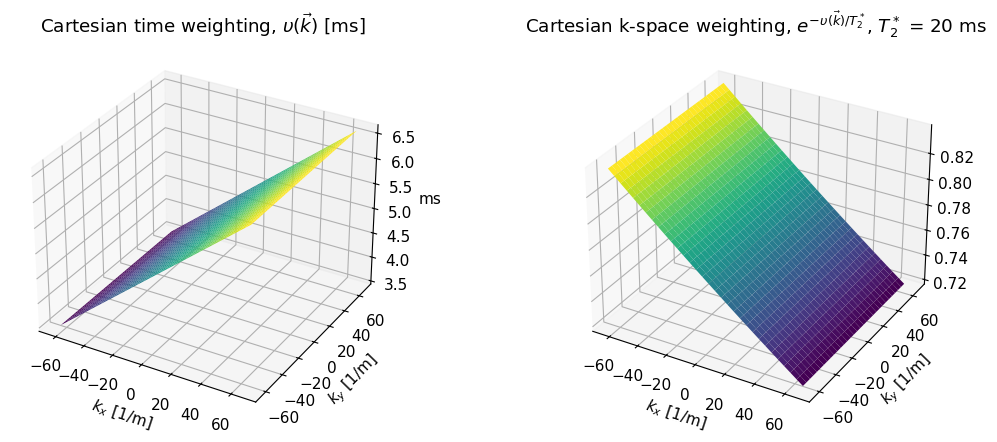

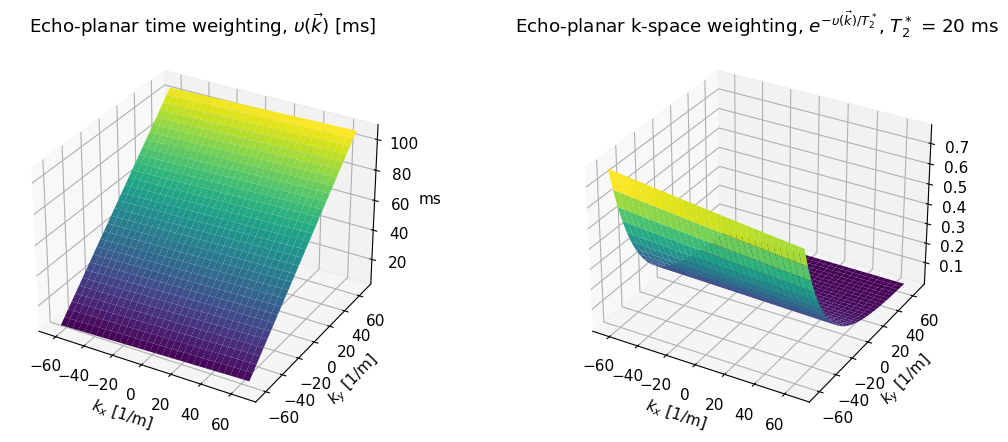

In [7]:
# Example k-space time maps upsilon(k) and resulting T2* k-space weighting (port of the original, SI units)
gamma_bar = mt.GAMMA_BAR          # [Hz/T]
N = 32
dt = 0.1e-3                       # dwell time [s] (0.1 ms, long, to make effects visible)
TE = 5e-3                         # echo time [s]
T2star = 20e-3                    # [s]
t = np.arange(-N / 2 + 1, N / 2 + 1) * dt          # readout time relative to the echo [s]
FOV = 0.24                                          # [m]
Gxr = 1 / (FOV * gamma_bar * dt)                   # readout gradient so that dk = gamma_bar*G*dt = 1/FOV [T/m]
kx0 = gamma_bar * Gxr * t                          # [1/m]
kx, ky = np.meshgrid(kx0, kx0)

# Cartesian (2DFT): time depends only on kx
upsilon_Cartesian = kx / (gamma_bar * Gxr) + TE    # [s]

# EPI: all N lines in one shot, tesp apart; the centre line is acquired at TE_epi
tesp = N * dt                                      # echo spacing [s] (no dead time, simplified)
TE_epi = TE + tesp * N / 2
tall = np.arange(-N**2 / 2 + 1, N**2 / 2 + 1) * dt + TE_epi
upsilon_EPI = np.reshape(tall, (N, N))             # row = ky line, consecutive in time
N_tm, tesp_tm = N, tesp                            # keep these (N and tesp are reused later in the notebook)

print(f"Gxr = {Gxr*1e3:.2f} mT/m, readout duration = {N*dt*1e3:.1f} ms, EPI echo spacing = {tesp*1e3:.1f} ms,"
      f" EPI centre-of-k-space time = {TE_epi*1e3:.1f} ms")

for name, ups in [("Cartesian", upsilon_Cartesian), ("Echo-planar", upsilon_EPI)]:
    fig = plt.figure(figsize=(12, 4.5))
    ax1 = fig.add_subplot(1, 2, 1, projection="3d")
    ax1.plot_surface(kx, ky, ups * 1e3, cmap="viridis")
    ax1.set_xlabel("$k_x$ [1/m]"); ax1.set_ylabel("$k_y$ [1/m]"); ax1.set_zlabel("ms")
    ax1.set_title(rf"{name} time weighting, $\upsilon(\vec k)$ [ms]")
    ax2 = fig.add_subplot(1, 2, 2, projection="3d")
    ax2.plot_surface(kx, ky, np.exp(-ups / T2star), cmap="viridis")
    ax2.set_xlabel("$k_x$ [1/m]"); ax2.set_ylabel("$k_y$ [1/m]")
    ax2.set_title(rf"{name} k-space weighting, $e^{{-\upsilon(\vec k)/T_2^*}}$, $T_2^*$ = {T2star*1e3:.0f} ms")
    plt.tight_layout(); plt.show()

For 2DFT the weighting is a gentle exponential tilt along $k_x$ only, and the same in every line. For EPI the time map spans ~100 ms along $k_y$, so with $T_2^* = 20$ ms the weighting falls by orders of magnitude from one edge of k-space to the other — essentially all the decay is in the **phase-encoding** direction.

The next cell computes the corresponding PSFs (convolution kernels) for $T_2^*$ = 100 ms and 10 ms. We use an inverse FFT with "backward" normalisation, so that the central PSF value equals the *mean* of $W$: a PSF peak of 1 means no signal loss.

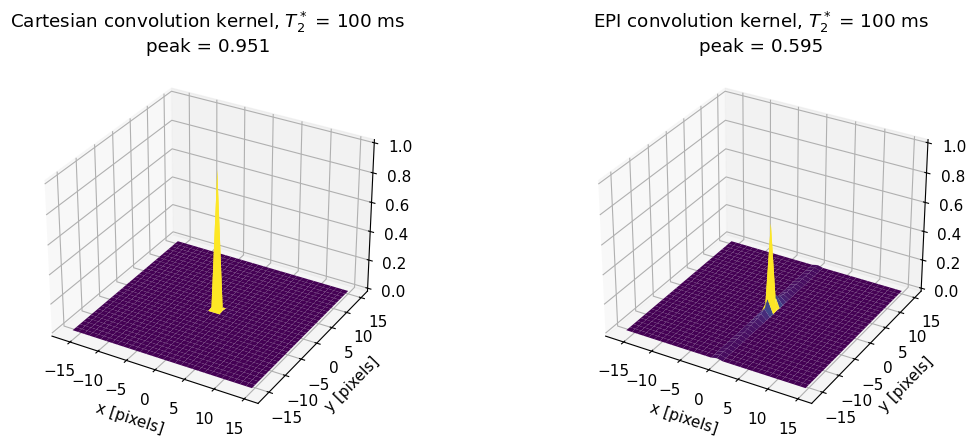

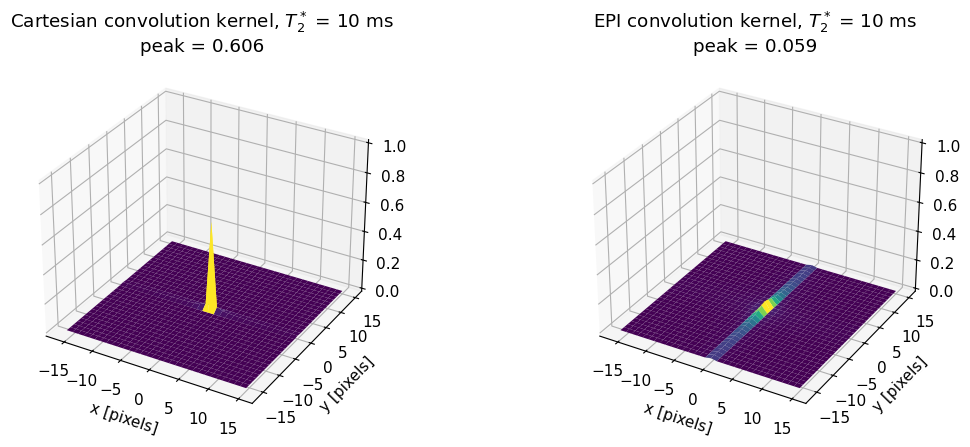

In [8]:
# Convolution kernels (PSFs) for T2* weighting  (the original's x, y axes were undefined; here: pixels)
xp = np.arange(N) - N // 2
X, Y = np.meshgrid(xp, xp)

for T2star in [100e-3, 10e-3]:
    W_Cartesian = mt.ifft2c(np.exp(-upsilon_Cartesian / T2star), norm="backward")
    W_EPI = mt.ifft2c(np.exp(-upsilon_EPI / T2star), norm="backward")
    fig = plt.figure(figsize=(12, 4.5))
    for i, (name, Wk) in enumerate([("Cartesian", W_Cartesian), ("EPI", W_EPI)]):
        ax = fig.add_subplot(1, 2, i + 1, projection="3d")
        ax.plot_surface(X, Y, np.abs(Wk), cmap="viridis")
        ax.set_xlabel("x [pixels]"); ax.set_ylabel("y [pixels]"); ax.set_zlim(0, 1)
        ax.set_title(rf"{name} convolution kernel, $T_2^*$ = {T2star*1e3:.0f} ms" + f"\npeak = {np.abs(Wk).max():.3f}")
    plt.tight_layout(); plt.show()

In the above plots, the height of the main peak in the centre represents the expected SNR, including losses due to blurring, while the signal amplitude outside the main peak represents the blurring that will occur. They show that the blurring and signal loss from $T_2^*$ get worse as the relaxation time gets shorter, and that blurring is much worse for EPI (in the phase-encoding direction) than for Cartesian trajectories. (Part of the low peak height is simply the amplitude factor $e^{-TE/T_2^*}$, which reduces signal but does not blur.)

### 4.2 Derivation: how wide is the $T_2^*$ blur?

Look at one direction (e.g. the readout, $x$) and separate the weighting into a constant and a $k$-dependent part. With $\upsilon(k_x)=TE+k_x/(\bar\gamma G_x)$ and $\bar\gamma G_x=\Delta k/\Delta t=BW_{read}/FOV$:

$$W(k_x)=\underbrace{e^{-TE/T_2^*}}_{\text{signal loss (contrast)}}\;\underbrace{e^{-a\,k_x}}_{\text{blur}},\qquad a=\frac{FOV}{BW_{read}\,T_2^*}$$

In words: a constant amplitude factor (which sets the $T_2^*$ *contrast* of the image), times an exponential "tilt" across k-space (which changes the PSF *shape*).
Where: $a$ [m] = how fast the weighting decays per unit $k_x$; $BW_{read}=1/\Delta t$ [Hz] total readout bandwidth; $FOV$ [m].

Over the whole readout the tilt changes the signal by a factor $e^{-T_{read}/T_2^*}$, so the single number that controls the blur is the ratio $T_{read}/T_2^*$.

**A clean special case — the spin echo.** In a spin echo the dephasing from field inhomogeneity ($T_2'$) is refocused at $t=TE$, and decays *on both sides* of the echo: $W(k_x)\propto e^{-|t-TE|/T_2'}=e^{-a|k_x|}$ (with $T_2'$ in place of $T_2^*$ in $a$). Its inverse FT (ignoring truncation) is a **Lorentzian**:

$$w(x)=\int_{-\infty}^{\infty}e^{-a|k|}e^{i2\pi kx}dk=\frac{2a}{a^2+(2\pi x)^2}$$

<details><summary><b>📐 Derivation (optional): the Lorentzian and its width</b></summary>

Split the integral at $k=0$: $\int_0^\infty e^{-(a-i2\pi x)k}dk+\int_0^\infty e^{-(a+i2\pi x)k}dk=\frac{1}{a-i2\pi x}+\frac{1}{a+i2\pi x}=\frac{2a}{a^2+4\pi^2x^2}$.

The peak (at $x=0$) is $2/a$. Half of it is reached when $a^2+4\pi^2x^2=2a^2$, i.e. $x=\pm a/(2\pi)$. Hence $FWHM=a/\pi$.

Convert to pixels by dividing by $\Delta x=FOV/N$, and use $N/BW_{read}=N\Delta t=T_{read}$:

$$FWHM_{pix}=\frac{a}{\pi\,\Delta x}=\frac{FOV}{\pi\,BW_{read}\,T_2'}\cdot\frac{N}{FOV}=\frac{T_{read}}{\pi\,T_2'}.$$

</details>

$$FWHM_{pixels}\approx\frac{T_{trav}}{\pi\,T_2^{(*)}}=\frac{1/(\pi T_2^{(*)})}{BW_{pix}}$$

In words: the blur, in pixels, is the time it takes to traverse k-space in that direction divided by $\pi T_2^{(*)}$. Equivalently: the **spectral line width** $1/(\pi T_2^*)$ [Hz] of the tissue, divided by the **bandwidth per pixel** — a frequency spread of Δν Hz is smeared over Δν/BW_pix pixels.
Where: $T_{trav}$ = $T_{read}$ for the readout direction, $N_{PE}\,t_{esp}$ for the EPI phase-encoding direction; $BW_{pix}=1/T_{trav}$ [Hz/pixel].

This is the asymptotic Lorentzian width; the total PSF is this Lorentzian convolved with the 1.21-pixel sampling sinc, so the extra blur only becomes noticeable once $T_{trav}/(\pi T_2^*)$ approaches one pixel, i.e. $T_{trav}\gtrsim 2$–$3\,T_2^*$. For the monotonic (gradient-echo / EPI) decay there is no simple closed form over a finite window; the next cell computes both cases numerically.

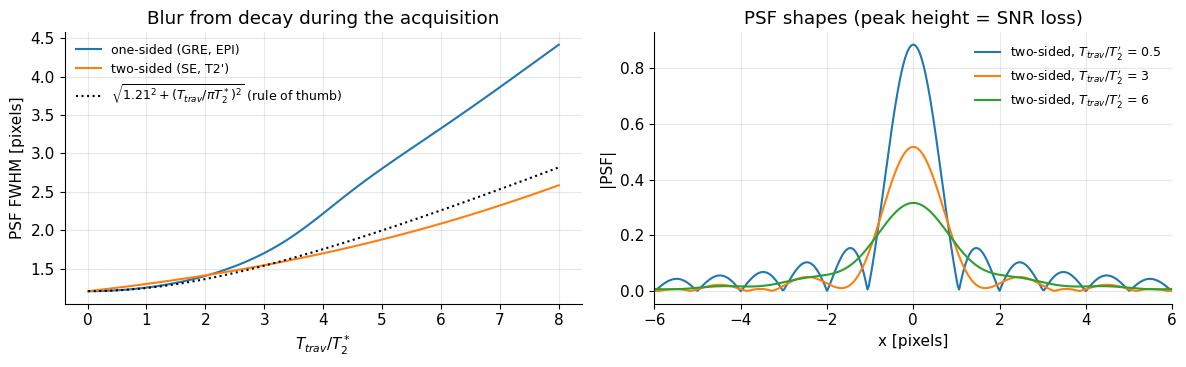

In [9]:
# Numerical PSF width versus T_trav / T2*, for one-sided (gradient echo / EPI) and two-sided (spin echo) decay
N = 128
pad = 32                                     # zero-padding factor for a smooth PSF
p = np.arange(N) - N // 2

def psf_1d(W, pad=pad):
    """PSF of a 1D k-space weighting W (length N), evaluated on a pad-times finer grid; peak 1 for W = 1."""
    Wz = np.zeros(len(W) * pad, complex)
    c = len(Wz) // 2
    Wz[c - len(W) // 2:c + len(W) // 2] = W
    return mt.ifftc(Wz, norm="backward") * pad

def fwhm_pixels(h, pad=pad):
    a = np.abs(h); c = np.argmax(a); half = a[c] / 2
    r = c + np.argmax(a[c:] < half); l = c - np.argmax(a[c::-1] < half)
    # linear interpolation at the half-maximum crossings
    rr = r - 1 + (a[r - 1] - half) / (a[r - 1] - a[r]); ll = l + 1 - (a[l + 1] - half) / (a[l + 1] - a[l])
    return (rr - ll) / pad

ratios = np.linspace(0.01, 8, 60)            # T_trav / T2*
res = {"one-sided (GRE, EPI)": [], "two-sided (SE, T2')": []}
for r in ratios:
    tt = p / N * r                           # (t - TE)/T2* for each sample; centre of k-space at TE
    res["one-sided (GRE, EPI)"].append(fwhm_pixels(psf_1d(np.exp(-tt))))
    res["two-sided (SE, T2')"].append(fwhm_pixels(psf_1d(np.exp(-np.abs(tt)))))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for lab, v in res.items():
    ax[0].plot(ratios, v, label=lab)
ax[0].plot(ratios, np.sqrt(1.207**2 + (ratios / np.pi)**2), "k:", label=r"$\sqrt{1.21^2+(T_{trav}/\pi T_2^*)^2}$ (rule of thumb)")
ax[0].set_xlabel(r"$T_{trav}/T_2^*$"); ax[0].set_ylabel("PSF FWHM [pixels]"); ax[0].legend(fontsize=9)
ax[0].set_title("Blur from decay during the acquisition")
xs = (np.arange(N * pad) - N * pad // 2) / pad
for r in [0.5, 3, 6]:
    tt = p / N * r
    ax[1].plot(xs, np.abs(psf_1d(np.exp(-np.abs(tt)))), label=fr"two-sided, $T_{{trav}}/T_2'$ = {r}")
ax[1].set_xlim(-6, 6); ax[1].set_xlabel("x [pixels]"); ax[1].set_ylabel("|PSF|"); ax[1].legend(fontsize=9)
ax[1].set_title("PSF shapes (peak height = SNR loss)")
plt.tight_layout(); plt.show()

The width grows only slowly at first (the sampling sinc dominates) and then roughly linearly with $T_{trav}/T_2^*$. The root-sum-square rule of thumb fits the two-sided (spin-echo) case well; the one-sided (gradient-echo/EPI) decay blurs more for the same $T_{trav}$ (about 10 % more at $T_{trav}=3T_2^*$, ~60 % more at $8T_2^*$), because its weighting falls by the full factor $e^{-T_{trav}/T_2^*}$ from one edge of k-space to the other, and its PSF becomes asymmetric and complex. The right panel also shows the second effect: the **peak drops** (lost SNR) while the tails grow.

> **🔧 Engineering reality:** In a 2DFT readout $T_{read}$ is 2–10 ms, far shorter than tissue $T_2^*$ (30–60 ms in brain at 3 T), so readout $T_2^*$ blur is negligible except for very short-$T_2^*$ tissues (tendon, cortical bone, lung, iron-loaded liver with $T_2^*$ of 0.1–5 ms, which need UTE/ZTE sequences). In single-shot EPI the phase-encoding traversal takes $N_{PE}t_{esp}\approx$ 64 × 0.5 ms = 32 ms or more — comparable to $T_2^*$ — so EPI images are noticeably blurred along PE. The cure is to *shorten the echo train*: stronger/faster gradients (shorter $t_{esp}$, limited by slew rate and nerve stimulation, see [Gradient System Engineering](B4_Gradient_System_Engineering.ipynb)), parallel imaging (skip lines, $N_{PE}/R$) or multi-shot segmentation.

## 5. PSF in the phase-encoding direction of echo trains (FSE and EPI)

In a **fast spin echo** (FSE, also TSE/RARE) sequence, one excitation is followed by $ETL$ refocusing pulses; echo number $n$ ($n=1,\dots,ETL$) occurs at $t_n=n\,t_{esp}$ and has amplitude $\propto e^{-n\,t_{esp}/T_2}$ (true $T_2$, because every echo is a spin echo). Each echo is phase-encoded differently, so different $k_y$ lines get **different amplitudes**. How the echoes are assigned to $k_y$ — the **view ordering** — defines the weighting $W(k_y)$ and therefore the PSF:

* **Linear (sequential) ordering:** echo 1 fills the band of lines at $-k_{max}$, the last echo fills $+k_{max}$; the echo that fills $k_y=0$ defines the **effective echo time** $TE_{eff}$ (the TE that sets the image contrast).
* **Centric ordering:** echo 1 fills the centre, later echoes go outward → $TE_{eff}=t_{esp}$ (proton-density/T1-like contrast) and a low-pass weighting → blur.
* **Late-centre ordering** (long $TE_{eff}$ for T2 weighting with the edges acquired early): the edges are *brighter* than the centre → high-pass weighting → edge enhancement and ringing.

The weighting is a **staircase** (constant within each band of $N_{PE}/ETL$ lines). We compute $W(k_y)$ and the PSF for a few tissues.

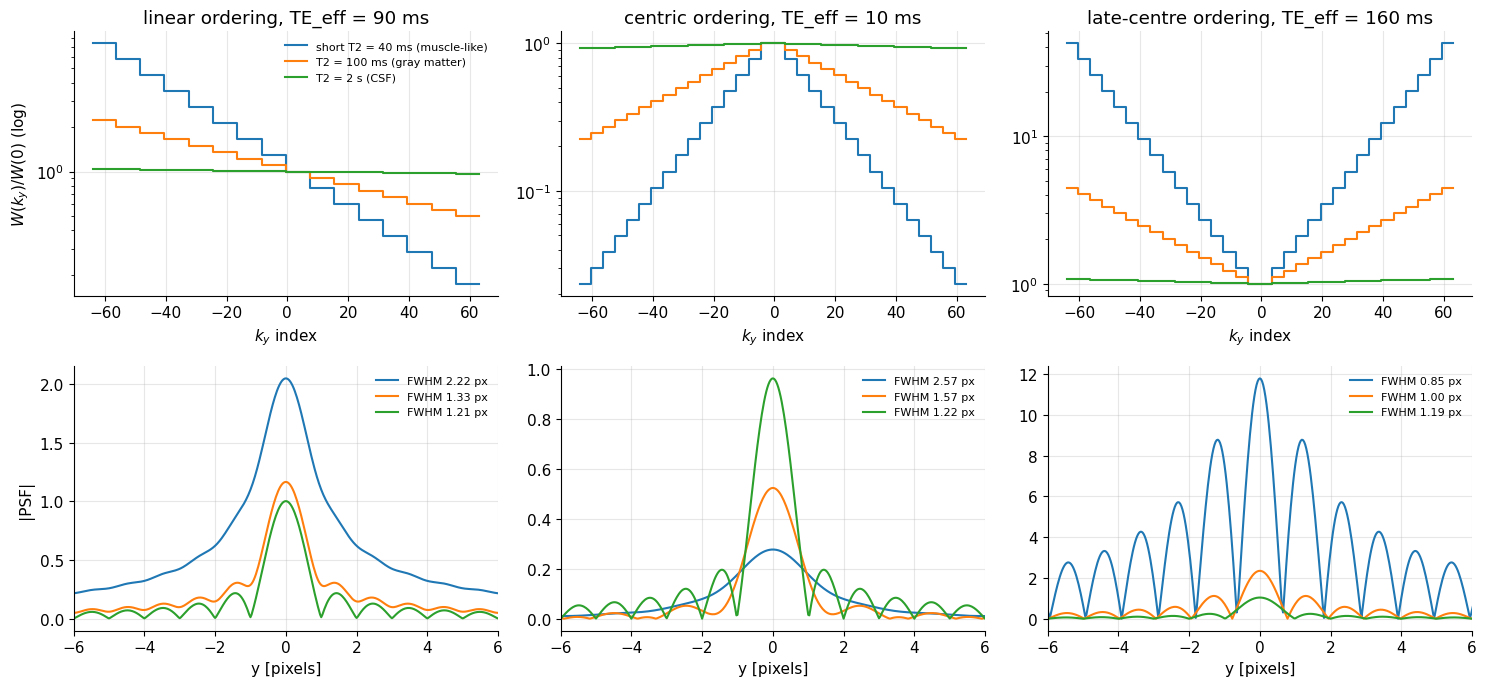

In [10]:
N_PE = 128
ETL = 16
tesp = 10e-3                                # FSE echo spacing [s]
lines_per_echo = N_PE // ETL
ky_idx = np.arange(N_PE) - N_PE // 2       # -64 .. 63

def fse_echo_index(order):
    """Echo number (1..ETL) used for each ky line (index 0 = most negative ky)."""
    band = np.arange(N_PE) // lines_per_echo                       # 0..ETL-1, linear in ky
    if order == "linear":
        return band + 1
    if order == "centric":                                         # centre first, then alternate outwards
        dist = np.abs(ky_idx + 0.5)                                # distance from the k-space centre
        return (np.argsort(np.argsort(dist, kind="stable"), kind="stable") // lines_per_echo) + 1
    if order == "late-centre":                                     # centre acquired with the LAST echo
        dist = np.abs(ky_idx + 0.5)
        return ETL - (np.argsort(np.argsort(dist, kind="stable"), kind="stable") // lines_per_echo)

tissues = {"short T2 = 40 ms (muscle-like)": 40e-3, "T2 = 100 ms (gray matter)": 100e-3, "T2 = 2 s (CSF)": 2.0}
xs = (np.arange(N_PE * pad) - N_PE * pad // 2) / pad
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j, order in enumerate(["linear", "centric", "late-centre"]):
    n_echo = fse_echo_index(order)
    TE_eff = n_echo[N_PE // 2] * tesp
    for lab, T2 in tissues.items():
        W = np.exp(-n_echo * tesp / T2) / np.exp(-TE_eff / T2)   # normalise to 1 at k = 0 (contrast factored out)
        ax[0, j].plot(ky_idx, W, drawstyle="steps-mid", label=lab)
        h = psf_1d(W)
        ax[1, j].plot(xs, np.abs(h), label=f"FWHM {fwhm_pixels(h):.2f} px")
    ax[0, j].set_title(f"{order} ordering, TE_eff = {TE_eff*1e3:.0f} ms")
    ax[0, j].set_xlabel("$k_y$ index"); ax[0, j].set_yscale("log")
    ax[1, j].set_xlim(-6, 6); ax[1, j].set_xlabel("y [pixels]"); ax[1, j].legend(fontsize=8)
ax[0, 0].set_ylabel(r"$W(k_y)/W(0)$ (log)"); ax[1, 0].set_ylabel("|PSF|")
ax[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

* **Linear:** the staircase decays across all of k-space. Long-$T_2$ CSF hardly changes; the short-$T_2$ tissue gets an asymmetric weighting (bright at $-k_y$, dark at $+k_y$) → mild blur plus slight ringing from the steps.
* **Centric:** a pure low-pass weighting for short $T_2$ → a clearly wider PSF (blur) for muscle-like tissue, while CSF is sharp. Blur depends on the tissue!
* **Late-centre:** edges amplified by up to $e^{(ETL-1)t_{esp}/T_2}$ relative to the centre → the PSF *narrows* but grows large negative sidelobes: edge enhancement and ringing (and the outer lines carry high signal, which boosts noise relative to the image intensity).

The same tool describes EPI: the weighting in $k_y$ is a smooth exponential instead of a staircase (one echo per line), and with $T_2^*$ instead of $T_2$.

> **🔧 Engineering reality:** Long echo trains are what make FSE fast (scan time ÷ ETL), but they are limited by (i) this $T_2$ blur, (ii) RF power deposition (SAR) from the many 180° pulses — often the real limit at 3 T — and (iii) the "stimulated echo" contributions when refocusing angles are reduced to save SAR. Vendors use variable refocusing flip angles (SPACE, CUBE, VISTA) to keep the echo amplitude flatter and the PSF narrower for 3D FSE with ETL > 100.

### 5.1 Tissue-dependent blur on a phantom (decomposition in action)

Because $T_2$ varies across the object, the system is not shift-invariant. We use the decomposition of Section 3.3: split the phantom into its tissue classes $m_i$ (each with one $T_2$), apply each class's weighting $W_i(k_y)$ in k-space, and add. The phantom is `mt.tissue_phantom` (1.5 T-like $T_2$ values).

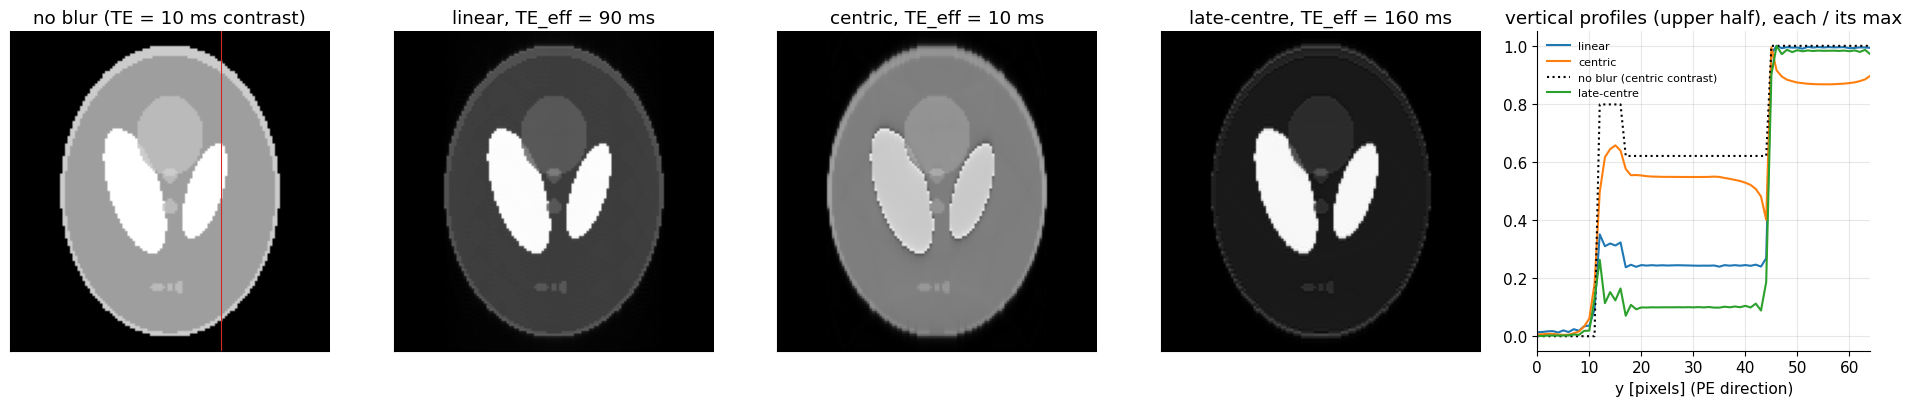

In [11]:
ph = mt.tissue_phantom(N_PE)
labels, T2map, M0 = ph["labels"], ph["T2"], ph["M0"]

def fse_image(order):
    """FSE image with T2 decay along the echo train, view ordering `order` (k-space rows = ky)."""
    n_echo = fse_echo_index(order)
    TE_eff = n_echo[N_PE // 2] * tesp
    Ksum = np.zeros((N_PE, N_PE), complex)
    for lab in np.unique(labels):
        if lab == 0:
            continue
        m_i = M0 * (labels == lab)                                   # component with a single T2
        T2_i = T2map[labels == lab][0]
        W_i = np.exp(-n_echo * tesp / T2_i)[:, None]                 # weighting along ky (rows), same for all kx
        Ksum += mt.fft2c(m_i) * W_i
    return mt.ifft2c(Ksum), TE_eff

fig, ax = plt.subplots(1, 5, figsize=(19, 4.2))
col = N_PE // 2 + 20                                                   # a column through skull, WM/GM and a ventricle
for a_, order in zip(ax[1:4], ["linear", "centric", "late-centre"]):
    img, TEe = fse_image(order)
    # reference: no blur, same contrast (each tissue scaled by exp(-TE_eff/T2))
    ref = M0 * np.exp(-TEe / T2map) * (labels > 0)
    mt.show_image(img, ax=a_, title=f"{order}, TE_eff = {TEe*1e3:.0f} ms")
    ax[4].plot(np.abs(img[:, col]) / np.abs(img[:, col]).max(), label=order)
    if order == "centric":
        mt.show_image(ref, ax=ax[0], title=f"no blur (TE = {TEe*1e3:.0f} ms contrast)")
        ax[4].plot(ref[:, col] / ref[:, col].max(), "k:", label="no blur (centric contrast)")
ax[0].axvline(col, color="C3", lw=0.8)
ax[4].set_xlim(0, N_PE // 2); ax[4].set_xlabel("y [pixels] (PE direction)"); ax[4].legend(fontsize=8)
ax[4].set_title("vertical profiles (upper half), each / its max")
plt.tight_layout(); plt.show()

The centric image shows a blurred skull ring (short $T_2$ "fat-like" tissue) and blurred white/grey matter, while the ventricles (CSF, $T_2$ = 2 s) stay sharp. With late-centre ordering ($TE_{eff}$ = 160 ms, heavily T2-weighted) the short-$T_2$ tissues show **edge enhancement and ringing**. Real FSE images show exactly these tissue-dependent effects.

## 6. Off-resonance and chemical shift

Off-resonance and chemical shift change the precession frequency of the magnetization. For simplicity, combine all off-resonance and/or chemical shift into a single frequency-shift term, $\Delta f(\vec{r}) = \Delta f_{cs} + \Delta f_r(\vec{r})$:

$$s(t) = \int m(\vec{r})\ e^{-i 2 \pi \Delta f(\vec{r}) t}\, e^{-i 2 \pi \vec{k}(t) \cdot \vec{r}} \  d\vec{r}$$

In words: each location accumulates an extra phase $2\pi\Delta f\,t$ that the reconstruction does not know about.
Where: $\Delta f(\vec r)$ [Hz] = total frequency offset of the spins at $\vec r$ relative to the receiver (demodulation) frequency.

Solving for the effect of frequency shifts requires specific knowledge of the k-space trajectory, and a spatially varying field further complicates the effect. However, some intuition can be gained by assuming a single frequency shift, $\Delta f(\vec{r}) = \Delta f_0$, which can then be taken out of the integral:

$$s(t) = e^{-i 2 \pi \Delta f_0 t} \int m(\vec{r})\ e^{-i 2 \pi \vec{k}(t) \cdot \vec{r}} \  d\vec{r} = M(\vec{k}(t))\  e^{-i 2 \pi \Delta f_0 t} $$

From this, we can see that the frequency shift leads to a **phase accumulation** as we acquire data across k-space. Using the time map $\upsilon(\vec{k})$ (also used for relaxation above):

$$\hat{M}(\vec{k}) = M(\vec{k})\, e^{-i 2 \pi\ \upsilon(\vec{k}) \Delta f_0},\qquad W(\vec{k}) = e^{-i 2 \pi\ \upsilon(\vec{k}) \Delta f_0}$$

Thus the reconstructed image will be corrupted by a convolution based on the k-space phase accumulation:

$$\hat{m}(\vec{r}) = m(\vec{r}) * \mathcal{F}^{-1} \{ e^{-i 2 \pi\ \upsilon(\vec{k}) \Delta f_0} \},\qquad w(\vec{r}) = \mathcal{F}^{-1} \{ e^{-i 2 \pi\ \upsilon(\vec{k}) \Delta f_0} \}$$

In words: a pure-phase weighting. If the phase is *linear* in $\vec k$, the PSF is a shifted delta (shift theorem); if it is non-linear, the PSF is a blur.

### 6.1 Displacement artifacts

For Cartesian and echo-planar sampling the time map is linear in $\vec k$, so the result is a **shift** (displacement) of the image.

> **🔁 Refresher (shift theorem):** $\mathcal F^{-1}\{e^{-i2\pi k x_0}\}=\delta(x-x_0)$ and $f(x)*\delta(x-x_0)=f(x-x_0)$: a linear phase ramp in k-space moves the image by $x_0$. [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb)

#### Cartesian sampling

In Cartesian sampling the phase accumulation occurs during the readout, which by convention is $k_x$. For 2D imaging we use $k_x(t) = \bar\gamma G_{x} t = \frac{BW_{read}}{FOV_x} t$ (neglecting a constant offset, which only gives a constant phase), so

$$\upsilon(k_x,k_y) = t = \frac{FOV_x}{BW_{read}}\, k_x$$

$$W(k_x,k_y) = e^{-i 2 \pi\ k_x \frac{FOV_x}{BW_{read}} \Delta f_0}$$

$$w(x, y) = \delta\!\left(x - \frac{\Delta f_0}{BW_{read}} FOV_x\right)\delta(y)$$

Convolution with a delta function is equivalent to a shift of the image in $x$:

$$\hat{m}(x,y) = m(x,y) * w(x,y) = m\!\left(x- \frac{\Delta f_0}{BW_{read}} FOV_x,\; y\right)$$

In words: the whole image is displaced along the readout direction by $\Delta x_{shift}=\frac{\Delta f_0}{BW_{read}}FOV_x$.
Where: $BW_{read}$ = total receiver bandwidth [Hz] (the original's $RBW$); $FOV_x$ [m]. *(Correction: the original wrote the PSF and the shifted image as functions of $k_x,k_y$; they are functions of position $x,y$.)*

**The key formula — shift in pixels.** Divide by the pixel size $\Delta x=FOV_x/N_x$:

$$\boxed{\;\text{shift [pixels]}=\frac{\Delta f_0\,N_x}{BW_{read}}=\frac{\Delta f_0}{BW_{pix}}=\Delta f_0\,T_{read}\;}$$

In words: the image moves by as many pixels as the frequency offset is a multiple of the **bandwidth per pixel**. Equivalently, the number of cycles of extra phase the spins accumulate while k-space is traversed.
Where: $BW_{pix}=BW_{read}/N_x=1/T_{read}$ [Hz/pixel].

#### EPI sampling

In EPI, the phase accumulation occurs primarily along the phase-encoding direction, $k_y$, because consecutive $k_y$ lines are separated by a whole echo spacing. Assume the phase accumulated during each readout is negligible and use $k_y(t) = \Delta k_y\, t / t_{esp} = \frac{BW_{PE}}{FOV_y} t$ (again neglecting a constant offset). Here a "phase-encoding bandwidth" is defined as the inverse of the echo spacing, $BW_{PE} = 1 / t_{esp}$.

$$\upsilon(k_x,k_y) = \frac{FOV_y}{BW_{PE}}\, k_y,\qquad W(k_x,k_y) = e^{-i 2 \pi\ k_y \frac{FOV_y}{BW_{PE}} \Delta f_0}$$

$$w(x, y) = \delta(x)\,\delta\!\left(y - \frac{\Delta f_0}{BW_{PE}} FOV_y\right),\qquad \hat{m}(x,y) =  m\!\left(x,\; y- \frac{\Delta f_0}{BW_{PE}} FOV_y\right)$$

In words: the same shift formula, now along $y$, with the much smaller "bandwidth" $1/t_{esp}$. In pixels: shift $=\Delta f_0\,N_{PE}\,t_{esp}=\Delta f_0/BW_{pix,PE}$, with $BW_{pix,PE}=1/(N_{PE}t_{esp})$.

Since the overall readout time is typically much longer in EPI than in Cartesian sampling, this leads to larger phase accumulations and larger shifts in the image. Equivalently, the phase-encoding bandwidths are typically much lower than readout bandwidths.

> **🧭 Intuition — the unifying rule:** in *any* direction where the time map is linear, a frequency offset $\Delta f$ shifts the image by $\Delta f\cdot T_{trav}$ pixels, where $T_{trav}$ is the time it takes to traverse k-space in that direction. Compare with Section 4.2: a frequency *spread* (line width) gives a *blur* of the same size.

In [12]:
# Realistic numbers: fat-water shift at 1.5 T and 3 T for typical 2DFT and EPI protocols
for B0 in [1.5, 3.0]:
    df_fat = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)                 # [Hz], negative
    print(f"B0 = {B0} T: fat offset = {df_fat:.0f} Hz")
    for name, BWread, Nx in [("2DFT, BW = +-16 kHz", 32e3, 256), ("2DFT, BW = +-62.5 kHz", 125e3, 256)]:
        BWpix = BWread / Nx
        print(f"   {name:24s} N={Nx}: BW/pixel = {BWpix:6.0f} Hz -> fat shift = {df_fat/BWpix:6.2f} pixels (readout)")
    for tesp_, Npe in [(0.5e-3, 64), (0.8e-3, 128)]:
        BWpix_pe = 1 / (Npe * tesp_)
        print(f"   EPI tesp = {tesp_*1e3:.1f} ms, N_PE = {Npe}:  BW/pixel (PE) = {BWpix_pe:5.1f} Hz -> fat shift = "
              f"{df_fat/BWpix_pe:6.1f} pixels (phase encoding)")

B0 = 1.5 T: fat offset = -224 Hz
   2DFT, BW = +-16 kHz      N=256: BW/pixel =    125 Hz -> fat shift =  -1.79 pixels (readout)
   2DFT, BW = +-62.5 kHz    N=256: BW/pixel =    488 Hz -> fat shift =  -0.46 pixels (readout)
   EPI tesp = 0.5 ms, N_PE = 64:  BW/pixel (PE) =  31.2 Hz -> fat shift =   -7.2 pixels (phase encoding)
   EPI tesp = 0.8 ms, N_PE = 128:  BW/pixel (PE) =   9.8 Hz -> fat shift =  -22.9 pixels (phase encoding)
B0 = 3.0 T: fat offset = -447 Hz
   2DFT, BW = +-16 kHz      N=256: BW/pixel =    125 Hz -> fat shift =  -3.58 pixels (readout)
   2DFT, BW = +-62.5 kHz    N=256: BW/pixel =    488 Hz -> fat shift =  -0.92 pixels (readout)
   EPI tesp = 0.5 ms, N_PE = 64:  BW/pixel (PE) =  31.2 Hz -> fat shift =  -14.3 pixels (phase encoding)
   EPI tesp = 0.8 ms, N_PE = 128:  BW/pixel (PE) =   9.8 Hz -> fat shift =  -45.8 pixels (phase encoding)


In 2DFT the fat shift is 1–4 pixels (tolerable, adjustable with the bandwidth); in single-shot EPI it is **tens of pixels** — a sizeable fraction of the FOV. This is why EPI is essentially always run with fat suppression.

The next cell is a port of the original's convolution-kernel plots for off-resonance (with the undefined `x, y` axes fixed). We use the same 32 × 32 time maps as in Section 4.1 ($t_{esp}$ = 3.2 ms) and choose $\Delta f$ = 1 and 10 "EPI pixels" ($\Delta f = 1/(N t_{esp})\approx$ 9.8 Hz and $10/(N t_{esp})\approx$ 98 Hz).

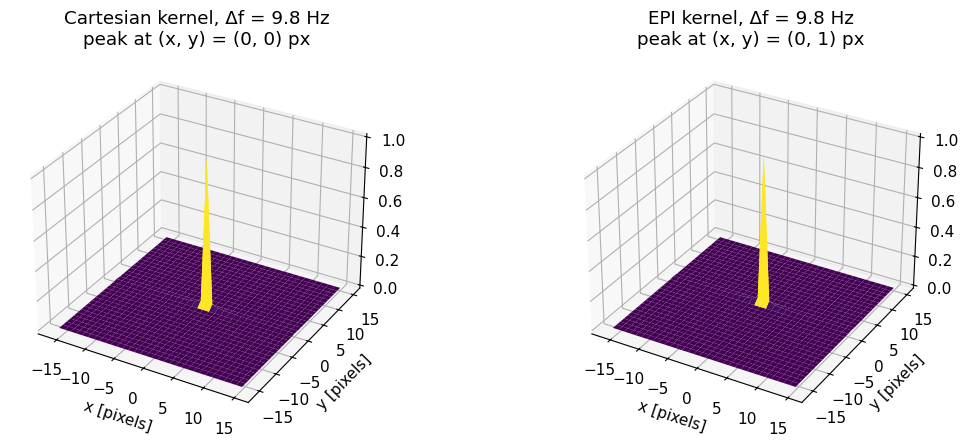

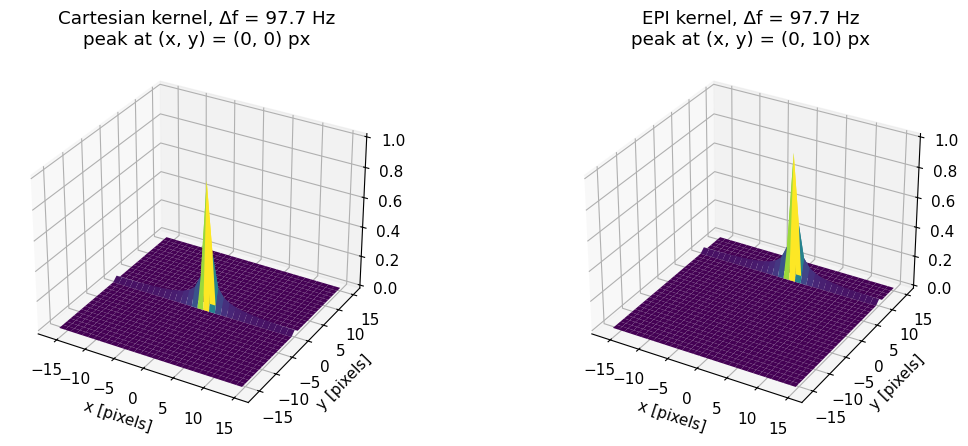

In [13]:
# Convolution kernels for off-resonance weighting (port of the original)
xp = np.arange(N_tm) - N_tm // 2
X, Y = np.meshgrid(xp, xp)                          # pixel coordinates of the 32 x 32 time maps
for n_pix in [1, 10]:
    df = n_pix / (N_tm * tesp_tm)                   # [Hz]: n_pix "EPI pixels" of shift
    W_Cartesian = mt.ifft2c(np.exp(-1j * 2 * np.pi * df * upsilon_Cartesian), norm="backward")
    W_EPI = mt.ifft2c(np.exp(-1j * 2 * np.pi * df * upsilon_EPI), norm="backward")
    fig = plt.figure(figsize=(12, 4.5))
    for i, (name, Wk) in enumerate([("Cartesian", W_Cartesian), ("EPI", W_EPI)]):
        ax = fig.add_subplot(1, 2, i + 1, projection="3d")
        ax.plot_surface(X, Y, np.abs(Wk), cmap="viridis")
        ax.set_xlabel("x [pixels]"); ax.set_ylabel("y [pixels]"); ax.set_zlim(0, 1)
        iy, ix = np.unravel_index(np.argmax(np.abs(Wk)), Wk.shape)
        ax.set_title(f"{name} kernel, Δf = {df:.1f} Hz\npeak at (x, y) = ({X[iy, ix]}, {Y[iy, ix]}) px")
    plt.tight_layout(); plt.show()

For a frequency shift, the main peak of the convolution kernel is moved away from the origin, which shifts the reconstructed image. The shift is much larger for EPI and is in the phase-encoding instead of the frequency-encoding direction (for $\Delta f\approx$ 98 Hz: 10 pixels in EPI, but only $98\ \text{Hz}\times3.2\ \text{ms}\approx0.3$ pixel in 2DFT — which shows up only as a slightly lowered peak). The residual side lobes in the Cartesian kernel are due to sinc interpolation for a non-integer shift, similar to Gibbs ringing (Section 2.2).

### 6.2 Checking the shift formula with a point source

We put a point at $x=0$ with an offset of $\Delta f_0$ = 600 Hz and read it out with $BW_{pix}$ = 250 Hz/pixel. The formula predicts a shift of 600/250 = 2.4 pixels.

predicted shift = df/BW_pix = 2.40 px; measured peak at 2.41 px


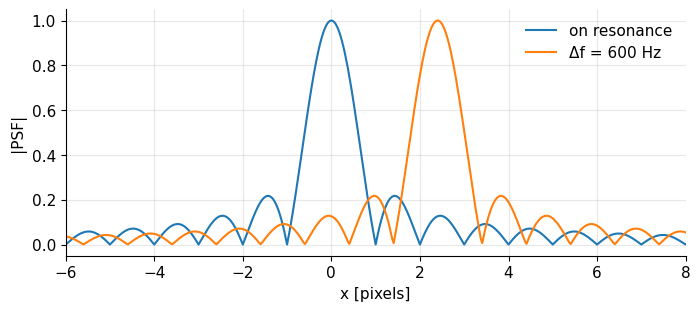

In [14]:
Nx = 128
BWread = 32e3                                   # total readout bandwidth [Hz] (+-16 kHz)
BWpix = BWread / Nx                             # [Hz/pixel]
df0 = 600.0                                     # [Hz]
p = np.arange(Nx) - Nx // 2
t_read = p / BWread                             # time of each sample relative to the echo [s] = upsilon - TE
M_point = np.ones(Nx)                           # k-space of a point at x = 0
W = np.exp(-1j * 2 * np.pi * df0 * t_read)      # phase accumulated by the off-resonant spins
h = psf_1d(M_point * W)
xs = (np.arange(Nx * pad) - Nx * pad // 2) / pad
print(f"predicted shift = df/BW_pix = {df0/BWpix:.2f} px; measured peak at {xs[np.argmax(np.abs(h))]:.2f} px")
plt.figure(figsize=(8, 3.2))
plt.plot(xs, np.abs(psf_1d(M_point)), label="on resonance")
plt.plot(xs, np.abs(h), label=f"Δf = {df0:.0f} Hz")
plt.xlim(-6, 8); plt.xlabel("x [pixels]"); plt.ylabel("|PSF|"); plt.legend(); plt.show()

The PSF is unchanged in shape — just displaced by exactly 2.4 pixels in the positive $x$ direction (for our sign conventions, a positive $\Delta f$ moves signal toward $+x$; fat, with negative $\Delta f$, moves toward $-x$).

### 6.3 Chemical shift displacement artifact

For the specific case of fat and water, we use the decomposition above to separate the two components, $m_1(\vec{r}) = m_{water}(\vec{r})$ for water and $m_2(\vec{r}) =  m_{fat}(\vec{r})$ for fat, with their own frequency shifts, $\Delta f_{water} = 0$ and $\Delta f_{fat}$, respectively. The weighting functions are then

$$W_{water}(\vec{k}) = 1, \qquad W_{fat}(\vec{k}) = e^{-i 2 \pi\ \upsilon(\vec{k}) \Delta f_{fat}}$$

and the resulting image will be

$$\hat{m}(\vec{r}) = m_{water}(\vec{r}) + m_{fat}(\vec{r}) * w_{fat}(\vec{r})$$

In words: water is imaged correctly, fat is imaged with its own (shifted) PSF, and the two images add.

In the case of Cartesian or echo-planar sampling, the water component will be accurately represented, while the fat component will be **shifted** in space. Where fat moves away from water there is a dark gap; where it moves onto water there is a bright overlap.

We simulate this on the tissue phantom at 3 T, treating label 1 (the "scalp" ring) as fat.

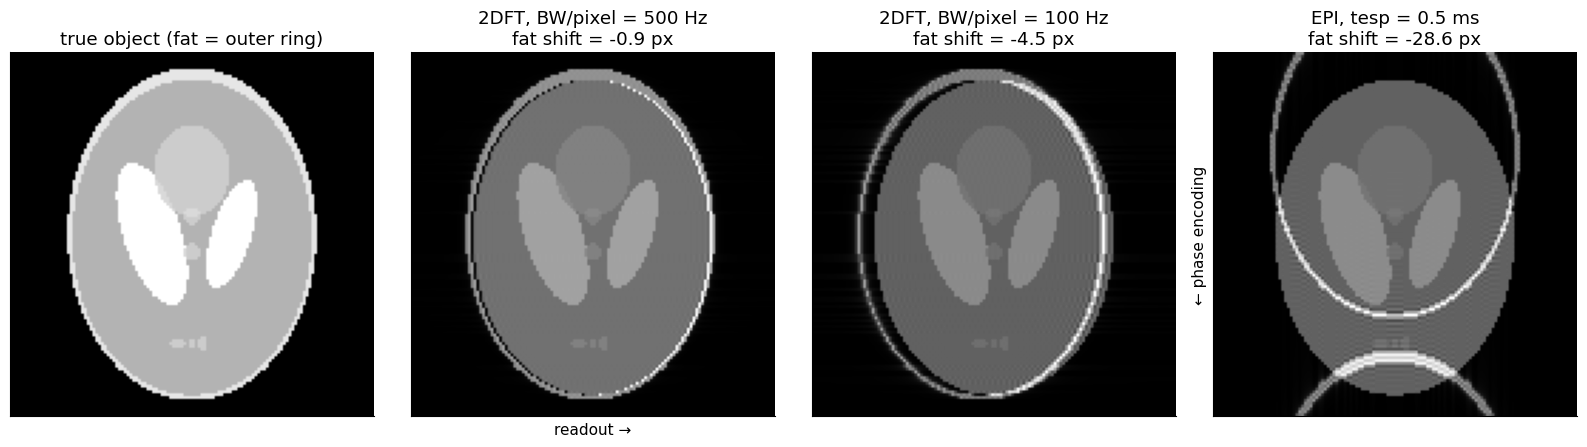

In [15]:
Nim = 128
ph = mt.tissue_phantom(Nim)
fat_mask = ph["labels"] == 1
m_water = ph["M0"] * (ph["labels"] > 1)
m_fat = ph["M0"] * fat_mask
df_fat = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 3.0)          # ~ -447 Hz at 3 T

pidx = np.arange(Nim) - Nim // 2
KX, KY = np.meshgrid(pidx, pidx)                       # k-space sample indices (columns = kx = readout, rows = ky)

def chem_shift_image(time_map):
    """Water + fat image for a given time map upsilon(k) [s] (array Nim x Nim, relative to TE)."""
    W_fat = np.exp(-1j * 2 * np.pi * df_fat * time_map)
    return mt.ifft2c(mt.fft2c(m_water) + mt.fft2c(m_fat) * W_fat)

cases = {
    "2DFT, BW/pixel = 500 Hz": KX / (Nim * 500.0),              # time = kx index * dwell, dwell = 1/(N BWpix)
    "2DFT, BW/pixel = 100 Hz": KX / (Nim * 100.0),
    "EPI, tesp = 0.5 ms": KY * 0.5e-3,                          # time = ky index * echo spacing
}
fig, ax = plt.subplots(1, 4, figsize=(16, 4.4))
mt.show_image(m_water + m_fat, ax=ax[0], title="true object (fat = outer ring)")
for a_, (name, tm) in zip(ax[1:], cases.items()):
    BWpix_eff = 1 / (np.ptp(tm) * Nim / (Nim - 1))
    mt.show_image(chem_shift_image(tm), ax=a_, title=f"{name}\nfat shift = {df_fat/BWpix_eff:.1f} px")
ax[1].set_xlabel("readout →"); ax[3].set_ylabel("← phase encoding")
plt.tight_layout(); plt.show()

At 500 Hz/pixel the fat ring moves by less than a pixel; at 100 Hz/pixel by 4.5 pixels (dark gap on one side, bright overlap on the other, along the readout direction); in EPI by ~28 pixels along the phase-encoding direction — the ring lands on the brain, as in the clinical example of the [Artifacts](I2_Artifacts.ipynb) chapter.

> **🔧 Engineering reality:** Raising $BW_{pix}$ shrinks the shift but costs SNR ($SNR\propto1/\sqrt{BW}$, see [Signal to Noise Ratio](G2_Signal_to_Noise_Ratio.ipynb)) and needs a stronger readout gradient, $G_x=BW_{read}/(\bar\gamma FOV_x)$: e.g. 125 kHz over a 24 cm FOV needs $G_x$ ≈ 12 mT/m — easy for modern 40–80 mT/m gradients, but the higher the gradient the faster the switching, the louder and the more eddy currents. Clinical protocols at 3 T typically use 200–400 Hz/pixel in 2DFT. The alternative is to remove fat signal altogether (fat saturation, STIR, Dixon water–fat separation, [In Vivo Contrast Mechanisms](D2_In_Vivo_Contrast_Mechanisms.ipynb)).

### 6.4 Other trajectories

In other trajectories, off-resonance and chemical shift do not appear as simple shifts. For example, they appear as a **blurring and ringing-like artifact for spiral and radial sampling**. The PSF framework still works: we only need the time map. For a "centre-out" trajectory (each readout starts at $\vec k=0$ and moves outward, as in spirals or centre-out radial), $\upsilon$ depends on $|\vec k|$ only: a centre-out radial spoke has $\upsilon\propto|\vec k|$, while an Archimedean spiral traversed at constant speed needs a path length — and hence a time — that grows like $|\vec k|^2$. We use the simple model $\upsilon(\vec k)=T_{read}\,(|\vec k|/k_{max})^{q}$ and evaluate $W$ on a Cartesian grid (this ignores the details of non-Cartesian gridding but shows the PSF shape correctly).

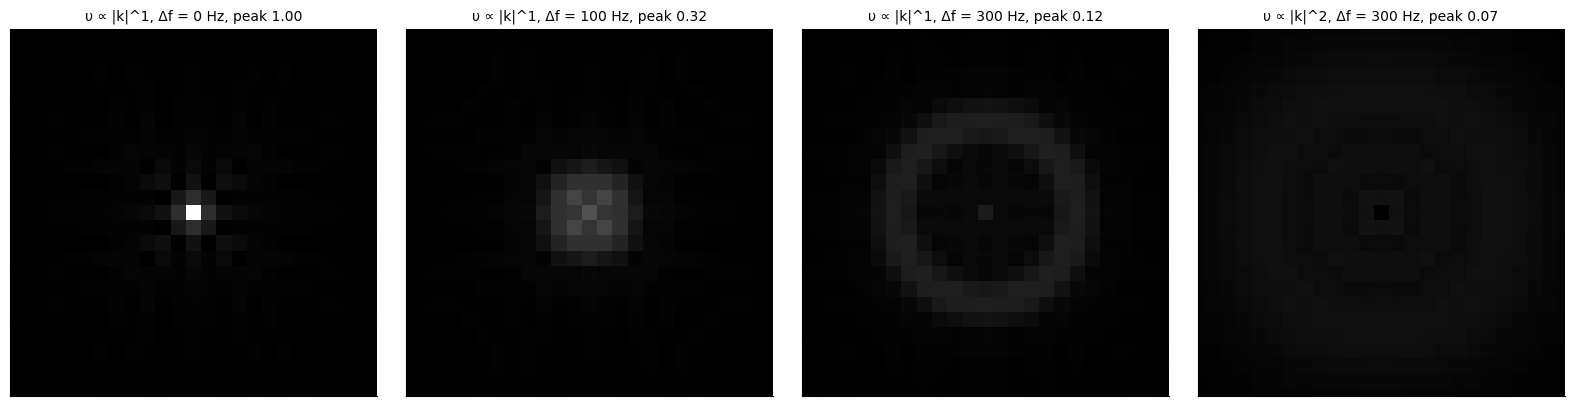

In [16]:
Nk = 128
kk = (np.arange(Nk) - Nk // 2) / (Nk // 2)          # k / kmax
KXn, KYn = np.meshgrid(kk, kk)
Kr = np.sqrt(KXn**2 + KYn**2)
disk = Kr <= 1.0                                    # circular k-space coverage
T_read_spiral = 10e-3                               # readout duration [s]
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a_, (q, df) in zip(ax, [(1, 0.0), (1, 100.0), (1, 300.0), (2, 300.0)]):
    ups = T_read_spiral * Kr**q
    W2 = disk * np.exp(-1j * 2 * np.pi * df * ups)
    psf = mt.ifft2c(W2, norm="backward") / disk.mean()
    mt.show_image(np.abs(psf), ax=a_, vmin=0, vmax=1,
                  title=f"υ ∝ |k|^{q}, Δf = {df:.0f} Hz\npeak = {np.abs(psf).max():.2f}")
    a_.set_xlim(Nk // 2 - 12, Nk // 2 + 12); a_.set_ylim(Nk // 2 - 12, Nk // 2 + 12)
    a_.set_title(f"υ ∝ |k|^{q}, Δf = {df:.0f} Hz, peak {np.abs(psf).max():.2f}", fontsize=10)
plt.tight_layout(); plt.show()

On resonance the PSF is a compact (jinc-shaped) spot. With off-resonance it is **not shifted but smeared** into a ring/halo, and the peak drops: a centre-out trajectory blurs off-resonant spins in all directions. This is why spiral imaging needs good shimming, short readouts and off-resonance correction (using a measured field map, see [Advanced Image Reconstruction](J5_Advanced_Image_Reconstruction.ipynb)).

## 7. Windowing (apodization): trading resolution for less ringing

The sampling PSF of Section 2 has −22 % sidelobes, which produce **Gibbs ringing** at sharp edges. We can deliberately multiply k-space by a smooth **window** (apodization) $W(k)$ that goes to (nearly) zero at $\pm k_{max}$ — a *chosen* k-space weighting. By the same convolution theorem, the PSF becomes the inverse FT of the window. Three quantities matter:

* **Main-lobe FWHM** (resolution): a window de-emphasises the high spatial frequencies, so the main lobe widens.
* **Peak sidelobe level** (ringing): smooth windows have much lower sidelobes.
* **SNR**: weighting k-space changes the signal and the noise differently. The signal of a large uniform region is set by the central value $W(0)$ (normalised to 1), while white k-space noise is scaled by the root-mean-square of $W$. For a small (point-like) feature the peak value is $\overline{W}$ (mean of $W$). A common figure of merit is the point-SNR factor $\sum_p W_p/\sqrt{N\sum_p W_p^2}$ (1 for the rect).

<details><summary><b>📐 Derivation (optional): SNR factor of a window</b></summary>

Measured data: $\hat M_p=W_p(M_p+n_p)$ with i.i.d. noise of variance $\sigma^2$ per sample. The inverse DFT at the location of a point object gives signal $\frac1N\sum_pW_pM_p$; for a point, $M_p=$ const $=A$, so the signal is $A\overline{W}$. The noise in that pixel is $\frac1N\sum_pW_pn_p$, with variance $\frac{\sigma^2}{N^2}\sum_pW_p^2$. SNR relative to $W\equiv1$ (where signal $=A$, noise variance $=\sigma^2/N$):

$$\frac{SNR_W}{SNR_1}=\frac{\overline W}{\sqrt{\frac1N\sum_pW_p^2}}=\frac{\sum_pW_p}{\sqrt{N\sum_pW_p^2}}\le1$$

by the Cauchy–Schwarz inequality, with equality only for a constant $W$. So *any* window lowers the peak-SNR of point-like features — but it also reduces the noise in large flat regions (where SNR improves by $W(0)/\mathrm{rms}(W)$, since it acts as a low-pass filter). Windows trade resolution for SNR.

</details>

window              FWHM [px]  peak sidelobe [dB]  point-SNR factor  flat-region SNR
rect (none)              1.21               -13.3              1.00             1.00
Tukey (α = 0.5)          1.60               -15.1              0.90             1.22
Hamming                  1.84               -42.4              0.85             1.60
Hann (Hanning)           2.03               -31.5              0.81             1.64
Kaiser (β = 6)           1.98               -44.0              0.82             1.66


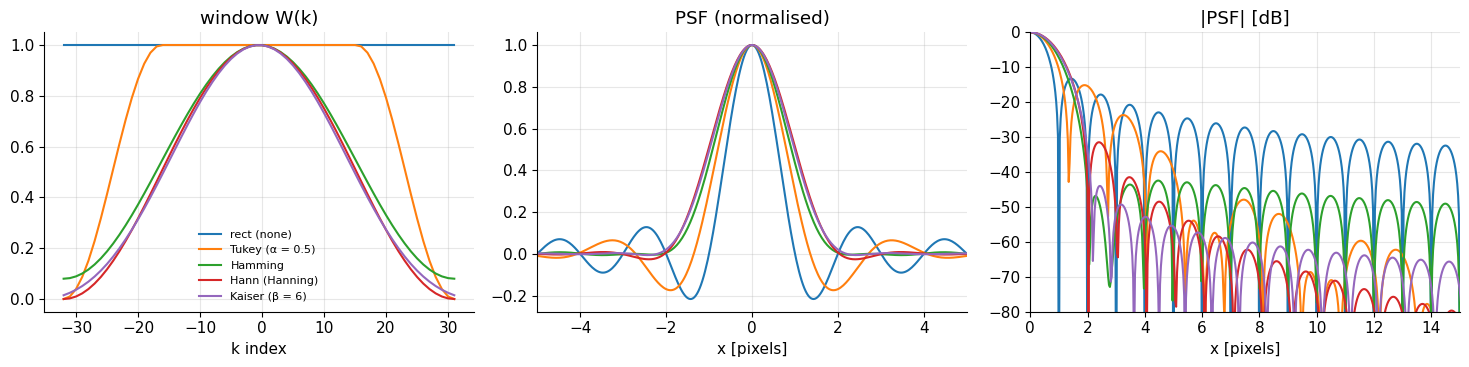

In [17]:
from scipy.signal import windows
N = 64
win = {
    "rect (none)": np.ones(N),
    "Tukey (α = 0.5)": windows.tukey(N, 0.5),
    "Hamming": np.hamming(N),
    "Hann (Hanning)": np.hanning(N),
    "Kaiser (β = 6)": windows.kaiser(N, 6),
}

def peak_sidelobe_db(h):
    a = np.abs(h); c = np.argmax(a)
    r = c
    while r + 1 < len(a) and a[r + 1] <= a[r]:      # walk down the main lobe to the first minimum
        r += 1
    return 20 * np.log10(a[r:].max() / a[c])

xs = (np.arange(N * pad) - N * pad // 2) / pad
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
print(f"{'window':18s} {'FWHM [px]':>10s} {'peak sidelobe [dB]':>19s} {'point-SNR factor':>17s} {'flat-region SNR':>16s}")
for name, w in win.items():
    h = psf_1d(w)
    snr_point = w.sum() / np.sqrt(N * (w**2).sum())
    snr_flat = w[N // 2] / np.sqrt((w**2).mean())
    print(f"{name:18s} {fwhm_pixels(h):10.2f} {peak_sidelobe_db(h):19.1f} {snr_point:17.2f} {snr_flat:16.2f}")
    ax[0].plot(np.arange(N) - N // 2, w, label=name)
    ax[1].plot(xs, np.real(h) / np.abs(h).max(), label=name)
    ax[2].plot(xs, 20 * np.log10(np.abs(h) / np.abs(h).max() + 1e-6), label=name)
ax[0].set_title("window W(k)"); ax[0].set_xlabel("k index"); ax[0].legend(fontsize=8)
ax[1].set_xlim(-5, 5); ax[1].set_title("PSF (normalised)"); ax[1].set_xlabel("x [pixels]")
ax[2].set_xlim(0, 15); ax[2].set_ylim(-80, 0); ax[2].set_title("|PSF| [dB]"); ax[2].set_xlabel("x [pixels]")
plt.tight_layout(); plt.show()

The table quantifies the trade-off: the **Hamming** window lowers the peak sidelobe from −13 dB to about −42 dB (a factor ~30 in amplitude) at the cost of a 50 % wider main lobe (1.84 vs 1.21 pixels) and ~15 % lower point-SNR, while increasing SNR in flat regions. The Hann window has a slightly wider main lobe and higher near sidelobes than Hamming but its far sidelobes fall off faster. A Tukey window (flat top, cosine taper) is a mild compromise often used clinically.

Now on an object with sharp edges: the analytic disk phantom (`mt.disk_phantom_kspace`, computed directly in k-space so it is *not* band-limited, like real anatomy).

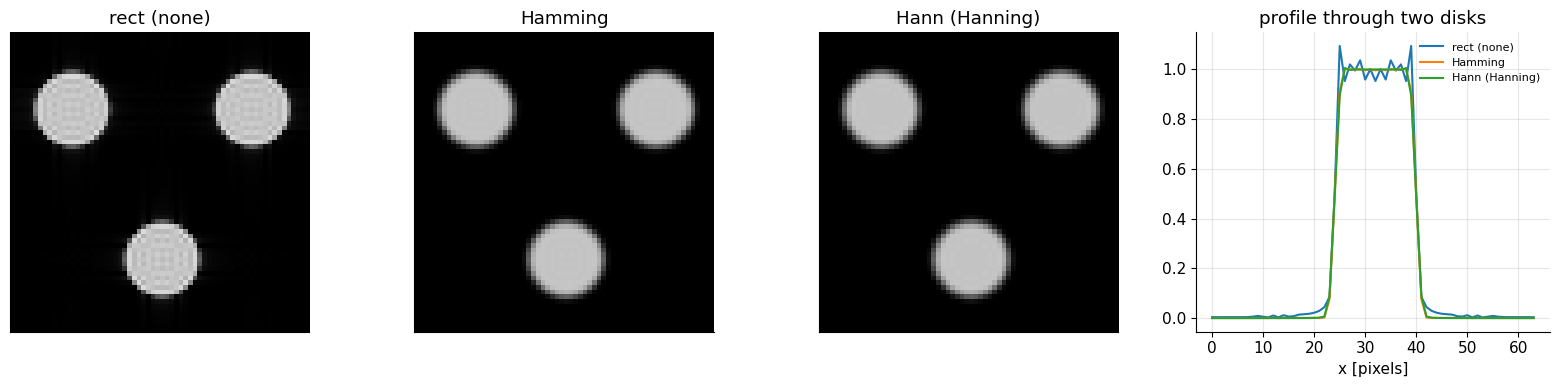

In [18]:
N = 64
K = mt.disk_phantom_kspace(N)
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a_, name in zip(ax[:3], ["rect (none)", "Hamming", "Hann (Hanning)"]):
    w2 = np.outer(win[name], win[name])                     # separable 2D window
    img = mt.ifft2c(K * w2)
    mt.show_image(img, ax=a_, title=name, vmin=0, vmax=1.15 * np.abs(mt.ifft2c(K)).max())
    ax[3].plot(np.abs(img[N // 2 + 16, :]), label=name)     # profile through the lower disks
ax[3].set_title("profile through two disks"); ax[3].set_xlabel("x [pixels]"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

Without a window, the disk edges overshoot and ripple (Gibbs ringing); with Hamming or Hann the ringing disappears and the edges become a little softer. In practice scanners apply mild filters by default (often adjustable as "filter" or "k-space filter" options), and the reader should know that the displayed resolution can be worse than the nominal pixel size.

> **⚠️ Common confusion:** "Resolution" in protocol cards = pixel size $\Delta x=FOV/N$. The *true* resolution (PSF FWHM) is ≥ 1.21 $\Delta x$, more with filtering, $T_2$ blur or partial-Fourier — and zero-filling/interpolation to a larger display matrix does **not** improve it.

## 8. Try it yourself

The cell below lets you combine the effects of this chapter on a 1D readout: number of samples, readout bandwidth, $T_2^*$ and off-resonance, and see the PSF. (Widgets only work in a live notebook; the static plot below shows the defaults.)

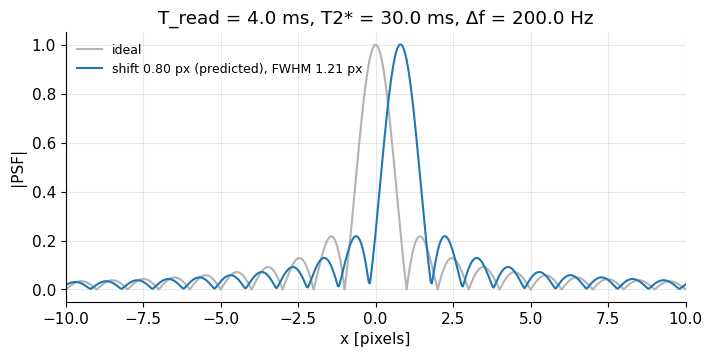

In [19]:
def plot_combined_psf(N=128, BWpix=250.0, T2star_ms=30.0, df=200.0, window="rect (none)", ax=None):
    """1D readout PSF combining finite sampling, T2* decay (gradient echo), off-resonance and a window."""
    p = np.arange(N) - N // 2
    t = p / (N * BWpix)                                       # time relative to the echo [s]
    w = {"rect (none)": np.ones(N), "Hamming": np.hamming(N), "Hann (Hanning)": np.hanning(N)}[window]
    W = w * np.exp(-t / (T2star_ms * 1e-3)) * np.exp(-1j * 2 * np.pi * df * t)
    h = psf_1d(W)
    xs = (np.arange(N * pad) - N * pad // 2) / pad
    ax = plt.gca() if ax is None else ax
    ax.plot(xs, np.abs(psf_1d(np.ones(N))), color="0.7", label="ideal")
    ax.plot(xs, np.abs(h), label=f"shift {df/BWpix:.2f} px (predicted), FWHM {fwhm_pixels(h):.2f} px")
    ax.set_xlim(-10, 10); ax.set_xlabel("x [pixels]"); ax.set_ylabel("|PSF|"); ax.legend(fontsize=9)
    ax.set_title(f"T_read = {1e3/BWpix:.1f} ms, T2* = {T2star_ms} ms, Δf = {df} Hz")

plt.figure(figsize=(8, 3.5)); plot_combined_psf(); plt.show()

In [20]:
try:
    from ipywidgets import interact, IntSlider, FloatSlider, Dropdown
    interact(lambda N, BWpix, T2star_ms, df, window: (plot_combined_psf(N, BWpix, T2star_ms, df, window), plt.show()),
             N=IntSlider(value=128, min=32, max=256, step=32),
             BWpix=FloatSlider(value=250, min=20, max=1000, step=10),
             T2star_ms=FloatSlider(value=30, min=1, max=200, step=1),
             df=FloatSlider(value=200, min=-500, max=500, step=10),
             window=Dropdown(options=["rect (none)", "Hamming", "Hann (Hanning)"]))
except ImportError:
    print("ipywidgets not available - edit the arguments of plot_combined_psf above instead.")

interactive(children=(IntSlider(value=128, description='N', max=256, min=32, step=32), FloatSlider(value=250.0…

## Key takeaways

* The **PSF** is the image of a point. MRI is (approximately) a linear shift-invariant system, so **image = object ∗ PSF**, and by the convolution theorem **PSF = $\mathcal F^{-1}$(whatever multiplies k-space)**.
* Finite, discrete sampling alone gives a **Dirichlet kernel** ≈ sinc: FWHM ≈ 1.21 pixels, −22 % first sidelobe (Gibbs ringing) and periodic replicas every FOV (aliasing).
* $T_2/T_2^*$ decay during the acquisition is an amplitude weighting $e^{-\upsilon(\vec k)/T_2^*}$: blur of roughly $T_{trav}/(\pi T_2^*)$ pixels plus SNR loss. Negligible for 2DFT readouts, important along PE in EPI and, tissue-dependently, in FSE (view ordering matters).
* Off-resonance $\Delta f$ is a phase weighting: for linear time maps it **shifts** the image by $\Delta f/BW_{pix}=\Delta f\,T_{trav}$ pixels (readout in 2DFT, PE in EPI); for centre-out trajectories it **blurs**.
* Fat at 3 T (−447 Hz) shifts ~1–4 pixels in 2DFT but tens of pixels in EPI.
* Spatially varying effects are handled by **decomposing** the object into components with one weighting each and summing.
* **Windowing** trades resolution (wider main lobe) and point-SNR for much lower sidelobes (Hamming: −42 dB).

## Check your understanding

1. A 2DFT scan at 3 T uses $N_x$ = 320 and $BW_{read}$ = ±40 kHz. How many pixels is fat shifted, and in which direction (readout or phase encoding)?

<details><summary>Answer</summary>

$BW_{read}$ = 80 kHz total → $BW_{pix}$ = 80 000/320 = 250 Hz/pixel. Fat offset ≈ −447 Hz → shift ≈ −1.8 pixels, along the **readout** direction (phase encoding has no time evolution between consecutive samples of a line in 2DFT, since every line has its own excitation and the same TE).

</details>

2. Why does a single bright point exactly at a pixel centre appear as one pixel, even though the PSF is a sinc?

<details><summary>Answer</summary>

The reconstructed image samples the PSF at the pixel centres, which coincide with the sinc's zeros (spaced exactly $\Delta x$). Any sub-pixel offset reveals the sidelobes (Section 2.2).

</details>

3. Single-shot EPI with $N_{PE}$ = 96, $t_{esp}$ = 0.6 ms, tissue $T_2^*$ = 25 ms. Estimate the extra PE blur and the shift of a region with $\Delta f$ = 50 Hz.

<details><summary>Answer</summary>

$T_{trav}=96\times0.6$ ms = 57.6 ms, so $T_{trav}/T_2^*\approx2.3$. Lorentzian estimate: 57.6/(π·25) ≈ 0.73 pixel on top of the 1.21-pixel sinc → ≈ 1.4 pixels by the rule of thumb; the numerical one-sided curve of Section 4.2 gives ≈ 1.5 pixels FWHM along PE. Shift = 50 Hz × 57.6 ms ≈ 2.9 pixels along PE.

</details>

4. You apply a Hamming window to reduce ringing. What do you lose?

<details><summary>Answer</summary>

Resolution: the PSF FWHM grows from ≈1.21 to ≈1.84 pixels. Also the peak SNR for small (point-like) features drops by ~15 %, while noise in flat regions is reduced (the window is a low-pass filter).

</details>

5. In an FSE with centric ordering, why is CSF sharp but a short-$T_2$ tissue blurred?

<details><summary>Answer</summary>

Centric ordering puts early (bright) echoes at the k-space centre and late echoes at the edges. For CSF ($T_2$ ≈ 2 s) all echoes have nearly the same amplitude ($W\approx1$) → no blur. For short $T_2$ the outer k-space lines are strongly attenuated → low-pass $W(k_y)$ → wide PSF.

</details>

6. For a spiral (centre-out) readout, why does off-resonance blur instead of shifting the image?

<details><summary>Answer</summary>

The time map $\upsilon(\vec k)$ depends on $|\vec k|$, not linearly on one component of $\vec k$. The phase weighting $e^{-i2\pi\Delta f\upsilon(|\vec k|)}$ is therefore not a linear phase ramp (which would give a shifted delta) but a radially symmetric phase pattern, whose inverse FT is a ring-like spread PSF.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Point Spread Function Analysis". Changes: added PSF/LSI/convolution introduction, Dirichlet-kernel derivation, aliasing replicas, Lorentzian $T_2^*$-blur derivation, FSE view-ordering PSFs, shift-in-pixels formula, centre-out trajectories, windowing trade-offs and numerical demos; fixed the PSF/shift formulas written in $k$ instead of $x$, the undefined axes in the original code, and typos ("frfom", "Cartsian", "frequnecy").*